# VS code cũng đẹp mà
Tui yêu cái đẹp, thấy cái gì đẹp là tui lưu lại hết à
Tui muốn sản phẩm mk làm ra có sự chỉnh chu, áp dụng được vào thực tiễn, thực sự có ích cho đời

In [1]:
# import libraries 

import numpy as np
import pandas as pd
import unicodedata
import re


#Vẽ biểu đồ
import matplotlib.pyplot as plt 

# Vẽ biểu đồ nhiệt
import seaborn as sns

from collections import Counter

c:\Users\HAN NGA\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


# 1. EDA

In [2]:
# review file data
filename = r"data_merged.csv"

df=pd.read_csv(filename)
df

,job_url,search_keyword,job_title,company_name,location,salary,date_posted,date_deadline,category,company_field,min_experience,note_to_combine,description,requirements,benefits,source,work_type,job_position,edu,mean_salary
0,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,2026-03-27,2026-04-26,Kiểm Toán,Ngân hàng,3.0,"Audit, Kiểm Toán, Kiểm Toán Viên Cao Cấp, Phân...",MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...,Trình độ chuyên môn: Tốt nghiệp đại học chính ...,Đào tạo|Khác,1,Full-time,Nhân viên,Đại học,NaN
1,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,2026-03-27,2026-04-26,Data Engineer/Data Analyst/AI,Hệ thống CNTT & Thiết bị,NaN,"AI, Khoa Học Máy Tính, Kỹ Thuật Phần Mềm","1) Tham gia thiết kế kiến trúc, phát triển chứ...","1) Tốt nghiệp đại học trở lên, chuyên ngành Kh...",Thưởng|Chăm sóc sức khoẻ,1,Full-time,Nhân viên,Ko yêu cầu,NaN
2,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,2026-03-27,2026-04-26,Tiếp Thị,Thời trang/Trang sức,3.0,"Quản Trị Hàng Hóa, Phân tích dữ liệu, Truyền t...","Mục đích vị trí công việc Triển khai, theo dõi...",1. Bằng cấp: Đại học Chuyên ngành: QTKD/Market...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,1,Full-time,Nhân viên,Đại học,NaN
3,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,2026-03-27,2026-04-26,Nông/Lâm/Ngư nghiệp,Nông nghiệp/Lâm nghiệp/Nuôi trồng thủy sản,1.0,"Giao Tiếp Đàm Phán, Nghiên Cứu Môi Trường, Ngh...",Mô tả công việc: 1. Quan hệ chính phủ & kết nố...,Tốt nghiệp cao đẳng trở lên (ưu tiên ngành nôn...,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,1,Full-time,Nhân viên,Cao đẳng,23000000.0
4,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,2026-03-27,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,Sản xuất,2.0,"Data Analysis, Industrial Engineering, Analysi...",POSITION SUMMARY We are recruiting an IE engin...,"KNOWLEDGE, SKILLS AND ABILITIES Bachelor's Deg...",Thưởng|Đào tạo|Khác,1,Full-time,Nhân viên,Đại học,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5257,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,15 Tr - 25 Tr VND,2026-06-11,2026-07-11,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",NaN,0.0,NaN,Masscom là doanh nghiệp công nghệ Việt Nam với...,1/ Kiến thức và kinh nghiệm. Tối thiểu 2 năm k...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,4,Full-time,Nhân viên,NaN,20000000.0
5258,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,18 Tr - 25 Tr VND,2026-06-11,2026-07-11,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",NaN,2.0,NaN,"Với vị trí này bạn sẽ tham gia nghiên cứu, thi...",1/ Kiến thức & Nền tảng. Tốt nghiệp Đại học ch...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,4,Full-time,Nhân viên,NaN,21500000.0
5259,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,Cạnh tranh,2026-06-10,2026-07-10,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",NaN,2.0,NaN,"Nghiên cứu, phát triển và triển khai các thuật...",Tốt nghiệp Đại học trở lên chuyên ngành Công n...,Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...,4,Full-time,Nhân viên,Đại học,NaN
5260,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co L

## 1.1 TỔNG QUAN

In [ ]:
# Thống kê mô tả dữ liệu định lượng
df.describe()

,min_experience,source,mean_salary
count,4795.000000,5262.000000,1.622000e+03
mean,2.934515,2.041999,2.876616e+07
std,2.038503,1.142043,1.801188e+07
min,0.000000,1.000000,2.000000e+05
25%,2.000000,1.000000,1.700000e+07
50%,3.000000,2.000000,2.491850e+07
75%,4.000000,3.000000,3.672200e+07
max,15.000000,4.000000,1.500000e+08


In [4]:
# Thống kê mô tả dữ liệu định tính
df.describe(include=['O'])

,job_url,search_keyword,job_title,company_name,location,salary,date_posted,date_deadline,category,company_field,note_to_combine,description,requirements,benefits,work_type,job_position,edu
count,5262,5262,5259,5216,5253,4843,5218,5226,5255,4225,3547,5236,5257,5212,5262,5262,4768
unique,5262,24,4166,2065,46,662,113,123,908,113,2976,4309,4422,1983,5,6,5
top,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,AI Engineer,Trang Văn hóa công ty,Hà Nội,Thương lượng,2026-04-16,2026-05-31,Data Engineer/Data Analyst/AI,IT - Phần mềm,"SAP, Consulting, Information Technology, SAP C...",Các phúc lợi dành cho bạn Thưởng 13th monthly ...,Các phúc lợi dành cho bạn Thưởng 13th monthly ...,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,Full-time,Nhân viên,Đại học
freq,1,2282,56,743,2487,1629,136,200,500,297,8,9,9,146,4956,3104,3201


In [6]:
# Đếm số giá trị NaN tại mỗi trường
df.isna().sum()

job_url               0
search_keyword        0
job_title             3
company_name         46
location              9
salary              419
date_posted          44
date_deadline        36
category              7
company_field      1037
min_experience      467
note_to_combine    1715
description          26
requirements          5
benefits             50
source                0
work_type             0
job_position          0
edu                 494
mean_salary        3640
dtype: int64

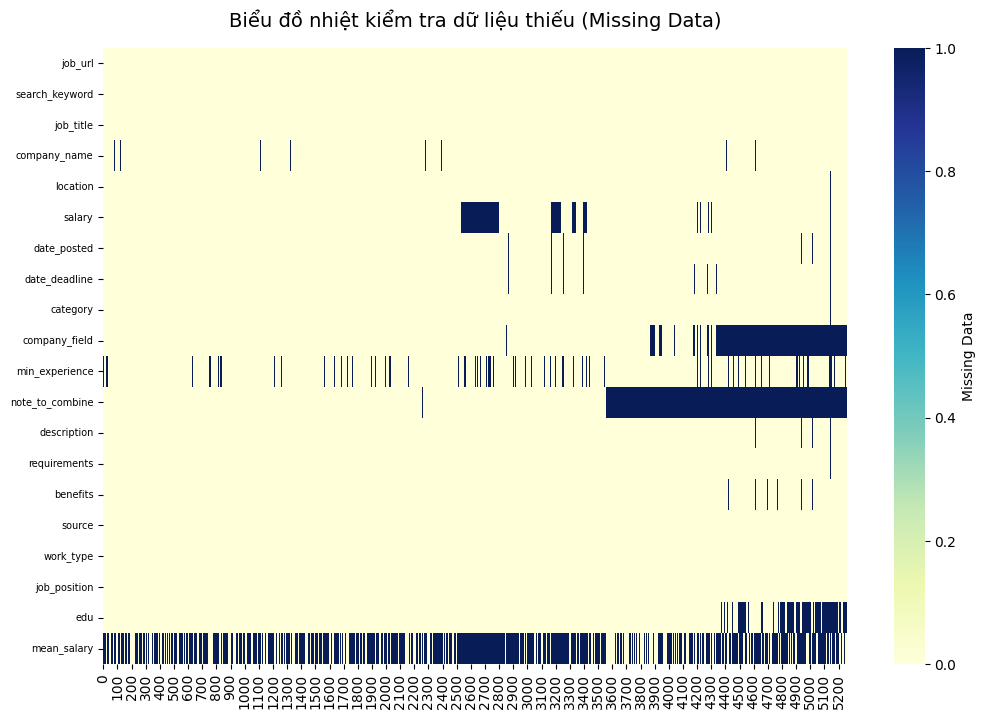

In [7]:

# Phát hiện dữ liệu bị thiếu
fig, ax = plt.subplots(figsize=(12, 8))

# Vẽ heatmap, transpose() để đảo cột thành trục Y giống như hình
sns.heatmap(df.isna().transpose(),
            cmap="YlGnBu", 
            cbar_kws={'label': 'Missing Data'})

plt.yticks(fontsize=7)
plt.title("Biểu đồ nhiệt kiểm tra dữ liệu thiếu (Missing Data)", fontsize=14, pad=15)
plt.show()


<Figure size 1000x1000 with 0 Axes>

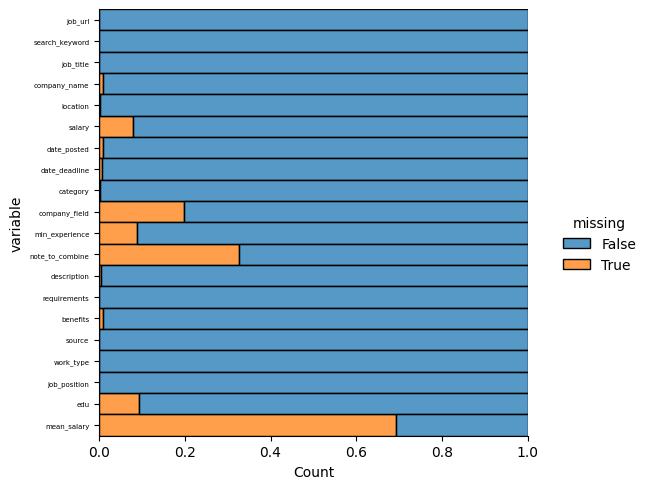

In [8]:
# % dữ liệu bị thiếu
plt.figure(figsize=(10,10))
sns.displot(
data=df.isna().melt(value_name="missing"),
y="variable",
hue="missing",
multiple="fill",
aspect=1.25
)
plt.yticks(fontsize=5)
plt.show()

$\color{orange}{\textbf{Phát hiện miss gần 70\% ở cột 'mean\_salary'}}$

- `Hơn 30%` còn lại của `5262 dòng data` = `1622 dòng`, là những dòng thông tin lương có con số rõ ràng.
- Về mặt Thống kê (Statistics) 1622 dòng là một "Mẫu" (Sample) rất lớn

## 1.2 Phân tích LƯƠNG

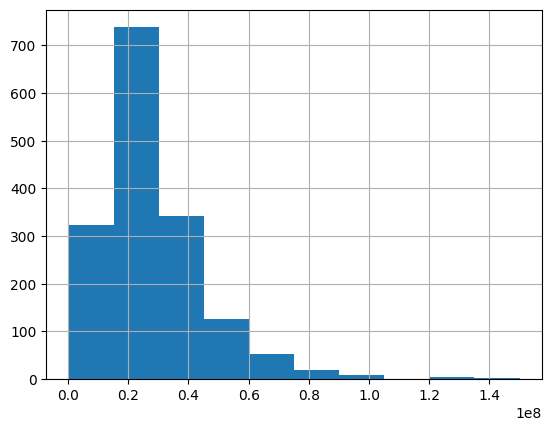

In [9]:
# Vẽ hist cho một cột `Mean_Salary`
df['mean_salary'].hist()
plt.show()

C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_868\1035102999.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


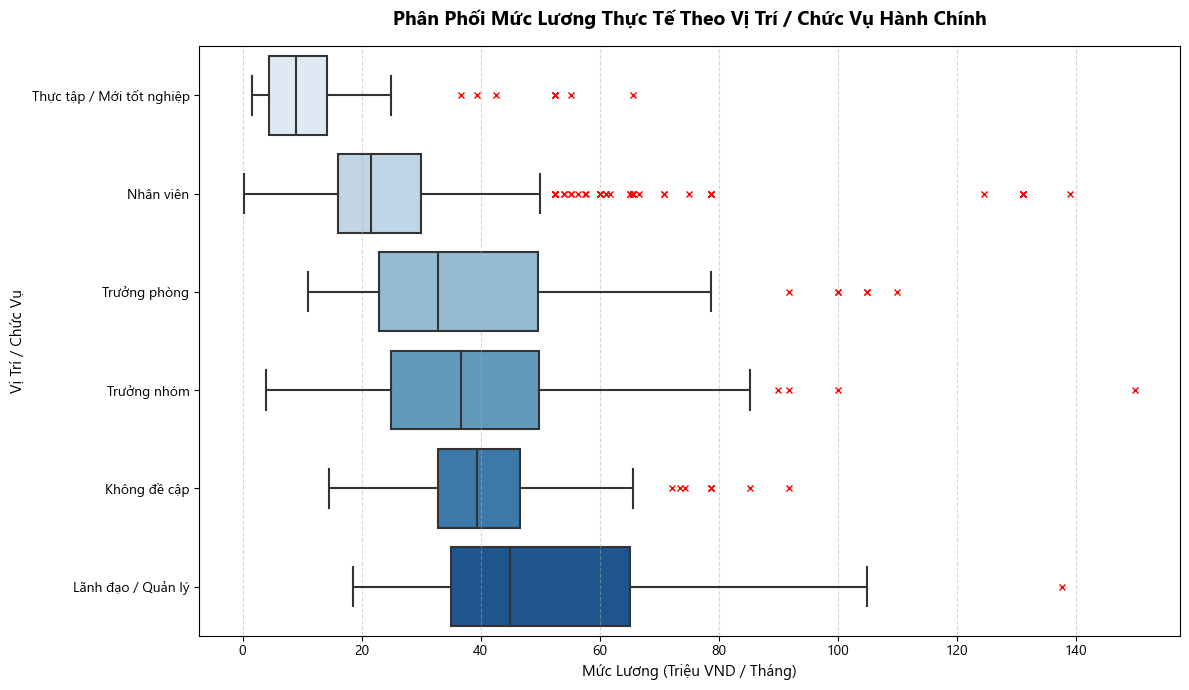

In [11]:
# LƯƠNG VÀ CHỨC VỊ

# 1. Cấu hình hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI'  # Hoặc 'Arial', 'Tahoma'
plt.figure(figsize=(12, 7))

# 2. Dọn dẹp dữ liệu trống (Null) trước khi vẽ
df_plot = df.dropna(subset=['mean_salary', 'job_position'])

# Quy đổi đơn vị lương sang "Triệu VND" cho trục tọa độ tinh tế, sạch sẽ
df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000

# Tự động tính trung vị (Median) lương để sắp xếp thứ tự các chức vụ từ thấp đến cao
order_positions = df_plot.groupby('job_position')['mean_salary_million'].median().sort_values().index

# 3. Vẽ biểu đồ Boxplot ngang
# Thuộc tính flierprops dùng để làm đẹp các chấm lương đột biến (Outliers)
sns.boxplot(
    data=df_plot,
    x='mean_salary_million',
    y='job_position',
    order=order_positions,
    palette='Blues',  # Hệ màu xanh dương chuyển sắc theo cấp bậc nhân sự
    flierprops={"marker": "x", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5} # Outliers màu đỏ gạch chéo
)

# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học xuất sắc
plt.title('Phân Phối Mức Lương Thực Tế Theo Vị Trí / Chức Vụ Hành Chính', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mức Lương (Triệu VND / Tháng)', fontsize=11)
plt.ylabel('Vị Trí / Chức Vụ', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)  # Lưới dọc mờ để dễ dóng hàng tiền

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


$\color{orange}{\textbf{Phát hiện quá nhiều giá trị Outlier ở các nhóm vị trí.}}$
$\color{orange}{\textbf{Giải pháp tối ưu nhất là}}$
- tính IQR riêng cho từng nhóm Vị trí công việc.
- Giữ lại toàn bộ dòng, nhưng biến giá trị lương bị Outlier đó thành NaN (Trống).

In [6]:
# Bước 1: Kiểm tra Outliers trong cột `mean_salary`

# Hàm kiểm tra Outlier dựa trên công thức IQR
def is_outlier(group):
    Q1 = group['mean_salary'].quantile(0.25)
    Q3 = group['mean_salary'].quantile(0.75)
    IQR = Q3 - Q1
    
    # Xác định giới hạn trên và dưới
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Trả về chuỗi True/False: True nếu nằm ngoài giới hạn (là Outlier)
    return (group['mean_salary'] < lower_bound) | (group['mean_salary'] > upper_bound)
# Tạo 1 cột tạm (True/False) đánh dấu xem dòng đó có phải Outlier hay không
# Lưu ý: group_keys=False giúp giữ nguyên index gốc của df
outlier_mask = df.groupby('job_position', group_keys=False).apply(is_outlier)

# Trích xuất các dòng bị coi là Outlier ra một dataframe mới để xem
outliers_df = df[outlier_mask]
print(f"🔥 Phát hiện tổng cộng {len(outliers_df)} dòng bị coi là Outliers!")
print("\n--- XEM THỬ 10 DÒNG OUTLIER ĐIỂN HÌNH ---")
outliers_df[['job_title', 'job_position', 'salary', 'mean_salary']]

🔥 Phát hiện tổng cộng 70 dòng bị coi là Outliers!

--- XEM THỬ 10 DÒNG OUTLIER ĐIỂN HÌNH ---


C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_2800\4121961160.py:20: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  outliers_df = df[outlier_mask]


,job_title,job_position,salary,mean_salary
91,Junior UA Performance Specialist,Nhân viên,"Tới $ 5,000 /tháng",131150000.0
100,Chuyên Gia Quản Trị Rủi Ro Tín Dụng (Lương Upt...,Nhân viên,50tr-70tr ₫/tháng,60000000.0
131,"Data Platform Lead, Legal Data Engineer, Data ...",Nhân viên,36tr-86tr ₫/tháng,61000000.0
153,"Creative Strategist (Up-To $5,000)",Nhân viên,"Tới $ 5,000 /tháng",131150000.0
154,"Performance Marketing Specialist (Ad Network, ...",Nhân viên,"Tới $ 5,000 /tháng",131150000.0
...,...,...,...,...
4036,AI Machine Learning Lead,Trưởng nhóm,Tới 100 triệu,100000000.0
4037,Kỹ Sư Dữ Liệu Lớn (Big Data Engineer ),Nhân viên,"800 - 3,500 USD",56394500.0
4039,Senior AI/LLM Engineer - Lương Upto 75 Triệu/T...,Nhân viên,Tới 75 triệu,75000000.0
4125,Senior AI Engineer (LLM/GenAI) - Up To $3000,Nhân viên,"Tới 3,000 USD",78690000.0


Tham khảo bài của anh Đỗ Quang Hùng 20185365. Anh có chuyển `salary` thành `mean_salary`, nhưng cuối cùng vẫn phân khúc.

- Dưới 3 triệu
- 3-10 triệu
- 10-15 triệu
- 15-25 triệu
- 25-35 triệu
- 35-50 triệu
- Trên 50 triệu

Nên t quyết định phân khúc trước, rồi mới xóa `mean_salary` các trường hợp Outlier.
- Phân khúc này là dành cho phần lọc ở Website
- Cần xóa Outlier là để đảm bảo đánh giá đúng khoảng lương đối với từng vị trí.

### 1.2.1 Tạo cột phân loại mức lương `salary_group`

In [8]:
# Tạo hàm phân loại mức lương
def categorize_salary(salary):
    if pd.isna(salary):
        return 'Thỏa thuận'
    elif salary / 1000000 < 3:
        return 'Dưới 3 triệu'
    
    elif salary / 1000000 <= 10:
        return '3-10 triệu'
    elif salary / 1000000 <= 15:
        return '10-15 triệu'
    
    elif salary / 1000000 <= 25:
        return '15-25 triệu'
    elif salary / 1000000 <= 35:
        return '25-35 triệu'
    elif salary / 1000000 <= 50:
        return '35-50 triệu'
    
    else:
        return 'Trên 50 triệu'

# Áp dụng tạo cột mới
df['salary_group'] = df['mean_salary'].apply(categorize_salary)

# Xem thử thống kê
df['salary_group'].value_counts()


salary_group
Thỏa thuận       3640
15-25 triệu       557
25-35 triệu       325
35-50 triệu       253
10-15 triệu       218
Trên 50 triệu     165
3-10 triệu         91
Dưới 3 triệu       13
Name: count, dtype: int64

### 1.2.2 Xử lý Outlier mean_salary

In [9]:
# 1. Định nghĩa hàm tìm Outlier bằng IQR
def detect_iqr_outliers(group):
    salary_data = group['mean_salary'].dropna()
    
    if len(salary_data) < 3: 
        return pd.Series(False, index=group.index)
        
    Q1 = salary_data.quantile(0.25)
    Q3 = salary_data.quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    is_outlier = (group['mean_salary'] < lower_bound) | (group['mean_salary'] > upper_bound)
    return is_outlier



# 2. Quét tìm Outlier
outlier_mask = df.groupby('job_position', group_keys=False).apply(detect_iqr_outliers)
print(f"Phát hiện {outlier_mask.sum()} dòng Outlier.")



# ----------------------------------------------------
# BƯỚC MỚI: TẠO CỘT mean_salary_fix
# ----------------------------------------------------
# 3. Copy toàn bộ dữ liệu từ cột gốc sang cột mới
df['mean_salary_fix'] = df['mean_salary']

# 4. Gán NaN cho các dòng Outlier nhưng CHỈ TRÊN CỘT MỚI
df.loc[outlier_mask, 'mean_salary_fix'] = np.nan

# In ra xem thử sự khác biệt
df[outlier_mask][['job_title', 'job_position', 'mean_salary', 'mean_salary_fix', 'salary_group']]


Phát hiện 70 dòng Outlier.


C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_6104\4038954048.py:36: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[outlier_mask][['job_title', 'job_position', 'mean_salary', 'mean_salary_fix', 'salary_group']]


,job_title,job_position,mean_salary,mean_salary_fix,salary_group
91,Junior UA Performance Specialist,Nhân viên,131150000.0,NaN,Trên 50 triệu
100,Chuyên Gia Quản Trị Rủi Ro Tín Dụng (Lương Upt...,Nhân viên,60000000.0,NaN,Trên 50 triệu
131,"Data Platform Lead, Legal Data Engineer, Data ...",Nhân viên,61000000.0,NaN,Trên 50 triệu
153,"Creative Strategist (Up-To $5,000)",Nhân viên,131150000.0,NaN,Trên 50 triệu
154,"Performance Marketing Specialist (Ad Network, ...",Nhân viên,131150000.0,NaN,Trên 50 triệu
...,...,...,...,...,...
4036,AI Machine Learning Lead,Trưởng nhóm,100000000.0,NaN,Trên 50 triệu
4037,Kỹ Sư Dữ Liệu Lớn (Big Data Engineer ),Nhân viên,56394500.0,NaN,Trên 50 triệu
4039,Senior AI/LLM Engineer - Lương Upto 75 Triệu/T...,Nhân viên,75000000.0,NaN,Trên 50 triệu
4125,Senior AI Engineer (LLM/GenAI) - Up To $3000,Nhân viên,78690000.0,NaN,Trên 50 triệu


C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_6104\3669107938.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['mean_salary_million'] = df_plot['mean_salary_fix'] / 1000000


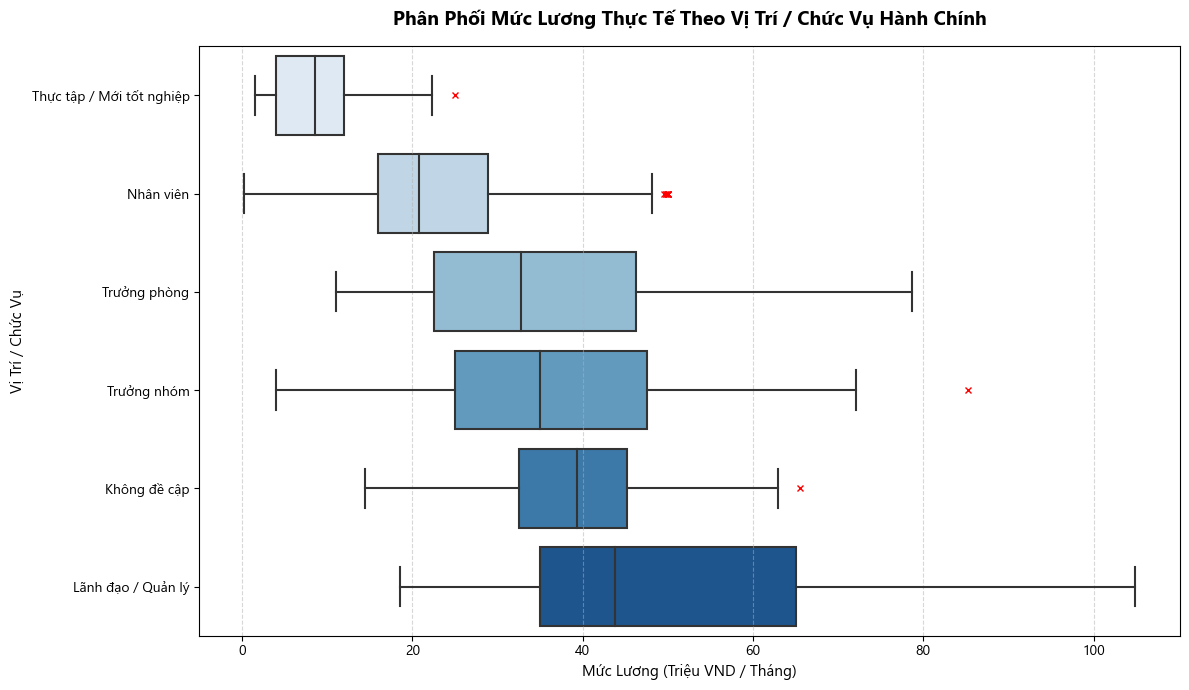

In [10]:
# LƯƠNG VÀ CHỨC VỊ đối với cột mean_salary_fix (đã loại bỏ Outlier)

# 1. Cấu hình hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI'  # Hoặc 'Arial', 'Tahoma'
plt.figure(figsize=(12, 7))

# 2. Dọn dẹp dữ liệu trống (Null) trước khi vẽ
df_plot = df.dropna(subset=['mean_salary_fix', 'job_position'])

# Quy đổi đơn vị lương sang "Triệu VND" cho trục tọa độ tinh tế, sạch sẽ
df_plot['mean_salary_million'] = df_plot['mean_salary_fix'] / 1000000

# Tự động tính trung vị (Median) lương để sắp xếp thứ tự các chức vụ từ thấp đến cao
order_positions = df_plot.groupby('job_position')['mean_salary_million'].median().sort_values().index

# 3. Vẽ biểu đồ Boxplot ngang
# Thuộc tính flierprops dùng để làm đẹp các chấm lương đột biến (Outliers)
sns.boxplot(
    data=df_plot,
    x='mean_salary_million',
    y='job_position',
    order=order_positions,
    palette='Blues',  # Hệ màu xanh dương chuyển sắc theo cấp bậc nhân sự
    flierprops={"marker": "x", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5} # Outliers màu đỏ gạch chéo
)

# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học xuất sắc
plt.title('Phân Phối Mức Lương Thực Tế Theo Vị Trí / Chức Vụ Hành Chính', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mức Lương (Triệu VND / Tháng)', fontsize=11)
plt.ylabel('Vị Trí / Chức Vụ', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)  # Lưới dọc mờ để dễ dóng hàng tiền

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


## 1.3 Phân tích năm kinh nghiệm tối thiểu

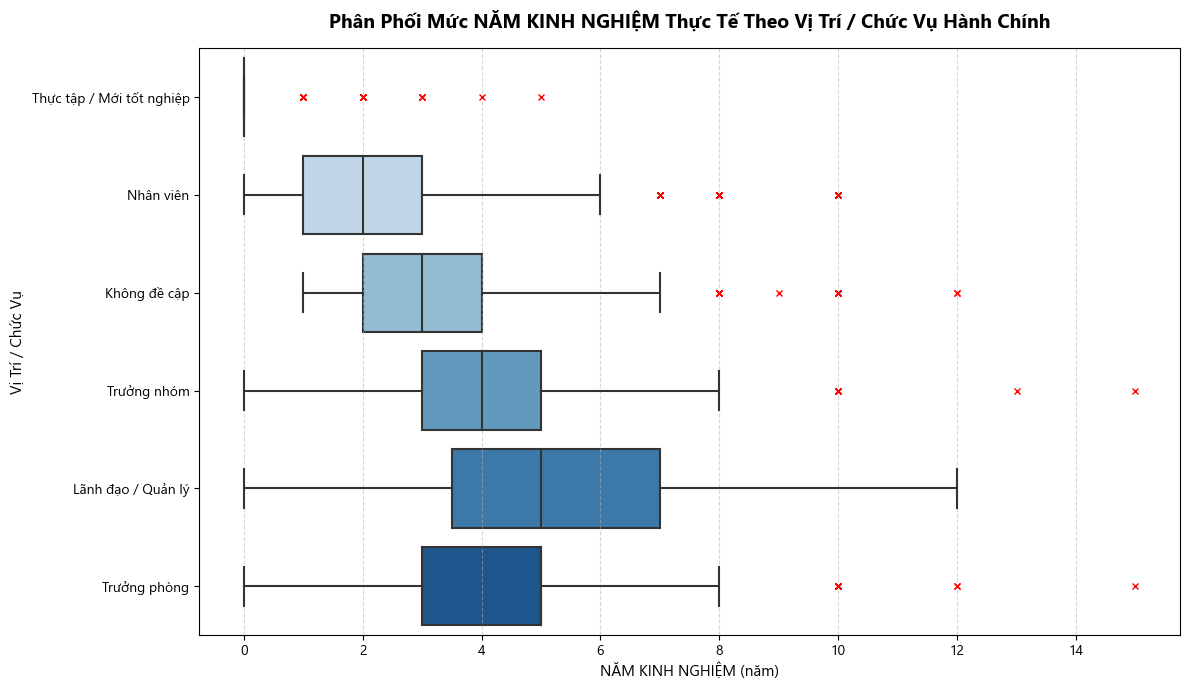

In [11]:
# NĂM KINH NGHIỆM VÀ CHỨC VỊ

# 1. Cấu hình hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI'  # Hoặc 'Arial', 'Tahoma'
plt.figure(figsize=(12, 7))

# 2. Dọn dẹp dữ liệu trống (Null) trước khi vẽ
df_plot = df.dropna(subset=['min_experience', 'job_position'])


# Tự động tính trung vị (Median) NĂM KINH NGHIỆM để sắp xếp thứ tự các chức vụ từ thấp đến cao
order_positions = df_plot.groupby('job_position')['min_experience'].median().sort_values().index

# 3. Vẽ biểu đồ Boxplot ngang
# Thuộc tính flierprops dùng để làm đẹp các chấm NĂM KINH NGHIỆM đột biến (Outliers)
sns.boxplot(
    data=df_plot,
    x='min_experience',
    y='job_position',
    order=order_positions,
    palette='Blues',  # Hệ màu xanh dương chuyển sắc theo cấp bậc nhân sự
    flierprops={"marker": "x", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5} # Outliers màu đỏ gạch chéo
)

# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học xuất sắc
plt.title('Phân Phối Mức NĂM KINH NGHIỆM Thực Tế Theo Vị Trí / Chức Vụ Hành Chính', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('NĂM KINH NGHIỆM (năm)', fontsize=11)
plt.ylabel('Vị Trí / Chức Vụ', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)  # Lưới dọc mờ để dễ dóng hàng tiền

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


$\color{orange}{\textbf{Phát hiện quá nhiều giá trị Outlier ở nhóm 'thực tập/ mới tốt nghiệp' là vô lý.}}$
- Cùng lắm chỉ là `dưới 2 năm` cho các chương trình Trainee, Fresher
- Nên chuyển Outlier nhóm `Thực tập/ mới tốt nghiệp` thành NULL
- Tạo cột mới `min_experience_fix`

$\color{orange}{\textbf{Sau khi ngẫm lại, thì t nghĩ nên xóa hết Outlier vì đây là đánh giá chung. Nhưng nhóm intern mới ra trường thường yêu cầu kinh nghiệm dưới 2 năm cũng là insight hay}}$
- Riêng `Thực tập/ mới tốt nghiệp` thì giữ `<= 2 năm`
- Còn các vị trí khác thì chuyển Outlier thành NULL

In [12]:
# Bước 1: Kiểm tra Outliers trong cột 'min_experience'

# Hàm kiểm tra Outlier dựa trên công thức IQR
def is_outlier(group):
    Q1 = group['min_experience'].quantile(0.25)
    Q3 = group['min_experience'].quantile(0.75)
    IQR = Q3 - Q1
    
    # Xác định giới hạn trên và dưới
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Trả về chuỗi True/False: True nếu nằm ngoài giới hạn (là Outlier)
    return (group['min_experience'] < lower_bound) | (group['min_experience'] > upper_bound)
# Tạo 1 cột tạm (True/False) đánh dấu xem dòng đó có phải Outlier hay không
# Lưu ý: group_keys=False giúp giữ nguyên index gốc của df
outlier_mask = df.groupby('job_position', group_keys=False).apply(is_outlier)

# Trích xuất các dòng bị coi là Outlier ra một dataframe mới để xem
outliers_df = df[outlier_mask]
print(f"🔥 Phát hiện tổng cộng {len(outliers_df)} dòng bị coi là Outliers!")
print("\n--- XEM THỬ 10 DÒNG OUTLIER ĐIỂN HÌNH ---")
outliers_df[['job_title', 'job_position', 'salary', 'min_experience']]

🔥 Phát hiện tổng cộng 162 dòng bị coi là Outliers!

--- XEM THỬ 10 DÒNG OUTLIER ĐIỂN HÌNH ---


C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_6104\2208793470.py:20: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  outliers_df = df[outlier_mask]


,job_title,job_position,salary,min_experience
13,Trợ Lý Tổng Giám Đốc,Nhân viên,Thương lượng,7.0
43,Expert/ Senior Business And Data Analyst,Nhân viên,Thương lượng,7.0
84,Chuyên Viên Đối Tác Nhân Sự (HRBP) cao cấp - H...,Nhân viên,Thương lượng,7.0
88,AI Engineer (GenAI/ Rag/ Agent),Thực tập / Mới tốt nghiệp,8tr-12tr ₫/tháng,1.0
111,Project Manager,Thực tập / Mới tốt nghiệp,Thương lượng,3.0
...,...,...,...,...
4306,Thực Tập Sinh Quay Dựng/Video Editor (Ứng Dụng...,Thực tập / Mới tốt nghiệp,2 - 4 triệu,1.0
4538,Chuyên gia Phân tích dữ liệu / Specialist of B...,Nhân viên,Cạnh tranh,7.0
4625,Advisor for Tracking and Monitoring of the NDC,Nhân viên,Cạnh tranh,10.0
4739,Manufacturing Engineering Lead,Nhân viên,Cạnh tranh,10.0


### 1.3.1 Xử lý Outlier `min_experience`

In [13]:
# 1. Tạo cột mới để bảo toàn dữ liệu gốc
df['min_experience_fix'] = df['min_experience']

# -------------------------------------------------------------------
# BƯỚC 1: XỬ LÝ NHÓM "THỰC TẬP / MỚI TỐT NGHIỆP"
# Xóa các dòng có min_experience > 2 (chỉ giữ lại <= 2)
# -------------------------------------------------------------------
mask_fresher = (df['job_position'] == 'Thực tập / Mới tốt nghiệp') & (df['min_experience_fix'] > 2)
df.loc[mask_fresher, 'min_experience_fix'] = np.nan
print(f"🔥 Đã biến {mask_fresher.sum()} Outlier của nhóm Thực tập (> 2 năm) thành NULL.")

# -------------------------------------------------------------------
# BƯỚC 2: DÙNG IQR TÌM OUTLIER CHO CÁC VỊ TRÍ KHÁC
# -------------------------------------------------------------------
def remove_iqr_exp(group):
    # Bỏ qua nhóm Thực tập vì đã làm bằng tay ở trên
    if group.name == 'Thực tập / Mới tốt nghiệp':
        return group
    
    exp_data = group['min_experience_fix'].dropna()
    if len(exp_data) < 3:
        return group
        
    Q1 = exp_data.quantile(0.25)
    Q3 = exp_data.quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Ép các giá trị nằm ngoài ranh giới thành NaN
    is_outlier = (group['min_experience_fix'] < lower_bound) | (group['min_experience_fix'] > upper_bound)
    group.loc[is_outlier, 'min_experience_fix'] = np.nan
    return group

# Áp dụng hàm IQR
df = df.groupby('job_position', group_keys=False).apply(remove_iqr_exp)

# In ra xem thử sự khác biệt
df[outlier_mask][['job_title', 'job_position','min_experience', 'min_experience_fix']]

🔥 Đã biến 5 Outlier của nhóm Thực tập (> 2 năm) thành NULL.


C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_6104\3656966311.py:40: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[outlier_mask][['job_title', 'job_position','min_experience', 'min_experience_fix']]


,job_title,job_position,min_experience,min_experience_fix
13,Trợ Lý Tổng Giám Đốc,Nhân viên,7.0,NaN
43,Expert/ Senior Business And Data Analyst,Nhân viên,7.0,NaN
84,Chuyên Viên Đối Tác Nhân Sự (HRBP) cao cấp - H...,Nhân viên,7.0,NaN
88,AI Engineer (GenAI/ Rag/ Agent),Thực tập / Mới tốt nghiệp,1.0,1.0
111,Project Manager,Thực tập / Mới tốt nghiệp,3.0,NaN
...,...,...,...,...
4306,Thực Tập Sinh Quay Dựng/Video Editor (Ứng Dụng...,Thực tập / Mới tốt nghiệp,1.0,1.0
4538,Chuyên gia Phân tích dữ liệu / Specialist of B...,Nhân viên,7.0,NaN
4625,Advisor for Tracking and Monitoring of the NDC,Nhân viên,10.0,NaN
4739,Manufacturing Engineering Lead,Nhân viên,10.0,NaN


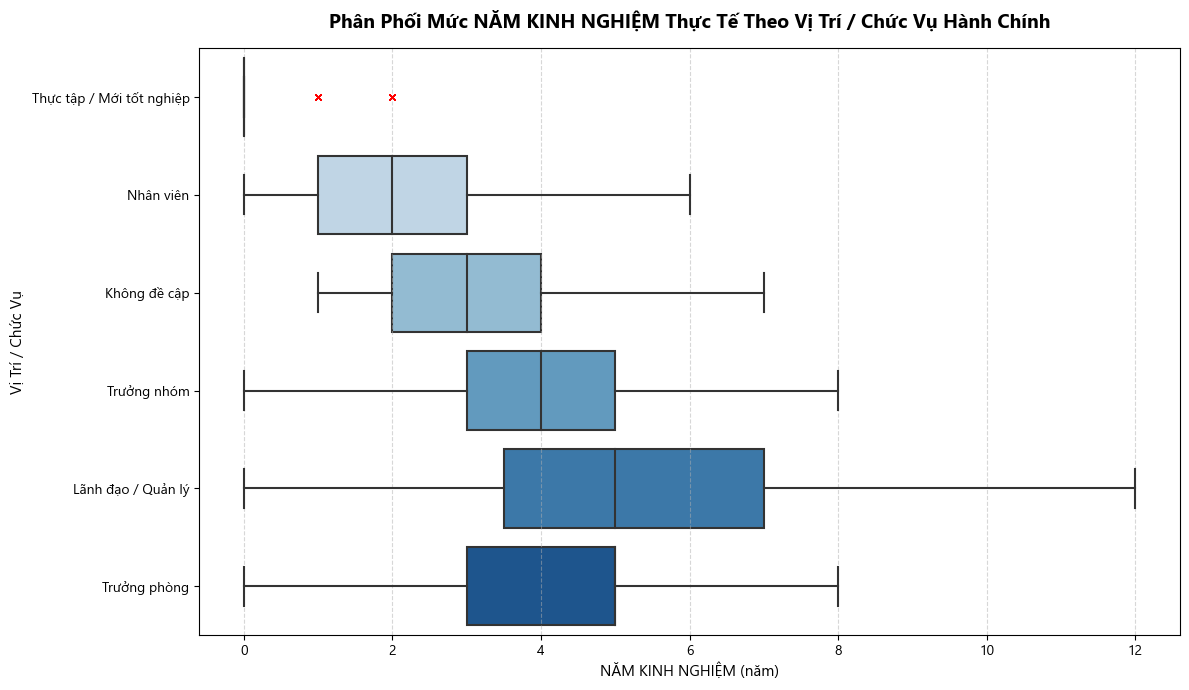

In [14]:
# NĂM KINH NGHIỆM VÀ CHỨC VỊ sau khi xử lý Outlier

# 1. Cấu hình hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI'  # Hoặc 'Arial', 'Tahoma'
plt.figure(figsize=(12, 7))

# 2. Dọn dẹp dữ liệu trống (Null) trước khi vẽ
df_plot = df.dropna(subset=['min_experience_fix', 'job_position'])


# Tự động tính trung vị (Median) NĂM KINH NGHIỆM để sắp xếp thứ tự các chức vụ từ thấp đến cao
order_positions = df_plot.groupby('job_position')['min_experience_fix'].median().sort_values().index

# 3. Vẽ biểu đồ Boxplot ngang
# Thuộc tính flierprops dùng để làm đẹp các chấm NĂM KINH NGHIỆM đột biến (Outliers)
sns.boxplot(
    data=df_plot,
    x='min_experience_fix',
    y='job_position',
    order=order_positions,
    palette='Blues',  # Hệ màu xanh dương chuyển sắc theo cấp bậc nhân sự
    flierprops={"marker": "x", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5} # Outliers màu đỏ gạch chéo
)

# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học xuất sắc
plt.title('Phân Phối Mức NĂM KINH NGHIỆM Thực Tế Theo Vị Trí / Chức Vụ Hành Chính', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('NĂM KINH NGHIỆM (năm)', fontsize=11)
plt.ylabel('Vị Trí / Chức Vụ', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)  # Lưới dọc mờ để dễ dóng hàng tiền

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


### 1.3.2 Thêm cột phân loại Năm Kinh nghiệm
- Dưới 1 năm
- 1-3 năm
- 3-5 năm
- 5-8 năm
- Trên 8 năm

In [5]:
# Tạo hàm phân loại số năm kinh nghiệm
def categorize_exp(experience):
    if pd.isna(experience):
        return None
    elif experience < 1:
        return 'Dưới 1 năm'
    
    elif experience <= 3:
        return '1-3 năm'
    elif experience <= 5:
        return '3-5 năm'
    
    elif experience <= 8:
        return '5-8 năm'
    
    else:
        return 'Trên 8 năm'

# Áp dụng tạo cột mới
df['exp_range'] = df['min_experience'].apply(categorize_exp)

# Xem thử thống kê
df['exp_range'].value_counts()

exp_range
1-3 năm       3073
3-5 năm       1017
Dưới 1 năm     356
5-8 năm        266
Trên 8 năm      83
Name: count, dtype: int64

# 2. THÊM CỘT MỚI

## 2.1 Phân loại nhóm ngành trong data
1. `Data Analytics / BI` (Phân tích, báo cáo)
2. `Data Engineer` (Xây dựng đường ống, hạ tầng)
3. `Data Science` (Khoa học dữ liệu)
4. `AI` (Trí tuệ nhân tạo)
5. `Database Management` (Quản trị cơ sở dữ liệu)

- Thực sự thì giờ Data Fullstack khá nhiều, DA thì học thêm tools rẽ hướng DE, AE. Nhiều người học chắc ML, thuật toán, Statistics, ... để thành DS. DS lại dùng ML để train AI.
- Nhánh full tools như Database thì lên DE chắc luôn.

=> Nên t nghĩ mk sẽ chia ra 5 cột. Nhưng Nhóm 5 với nhóm 2 trong thực tế, nó y chang nhau về tính chất à. Nên t gộp.

In [12]:

# 1. Khai báo từ điển chứa các từ khóa TỪ BỘ CODE CŨ CỦA BẠN (Đã gộp DE và Database)
keywords_dict = {

    # NHÓM PHÂN TÍCH DỮ LIỆU & BI (Thiên về phân tích, báo cáo, trực quan hóa dữ liệu)
    "related_data_analyst_bi": [
        "data analyst", "data analytics", "business intelligence", "data visualization", 
        "product analyst", "marketing analyst", "bi analyst", "bi developer",
        "data & reporting", "marketing intelligence", "demand analyst", "financial analyst", "market analyst",
        "phân tích dữ liệu", "phân tích khách hàng", "xử lý dữ liệu", "thống kê",
        "data analysis", "data & analytics", "data & system analyst", "data marketing", "data insight",
        "data specialist", "data executive", "fresher data", "operations analyst", "oparational data",
        "strategic data", "analytics engineer", "data translator",
        "financial analysis", "fraud analyst", "risk analyst", 
        "social media analyst", "web analyst", 
        "supply chain analyst", "crm analyst", "insights analyst", 
        "trading analyst",
        "research analyst", "power bi", "research & analyst",  "erp analyst", "performance marketing", "performance analyst", "performance ads" 
    ],
    
    # NHÓM XÂY DỰNG HỆ THỐNG & KỸ SƯ DỮ LIỆU
    "related_data_engineer": [
        # Keywords của Data Engineer cũ
        "data engineer", "data architect", "data warehouse", "etl", "bi developer", "mlops", 
        "analytics engineer", "cloud data", "big data engineer", "big data",
        "cloud data", "data architect", "master data management", "data system", "data systems",
        "kỹ sư dữ liệu", "kiến trúc giải pháp dữ liệu", "kiến trúc sư dữ liệu", "chuyên viên quản lý dữ liệu",
        "data platform", "data crawler", "data solution", "data migration", "data engineering", "data mart", "aws",
        "data integration", "data automation", "data processing", "data mesh", "ml engineer", "machine learning ops engineer", "mlops engineer",
        # Keywords của Database Management cũ
        "database administrator", "dba", "data modeler", "data governance", "data quality", "database developer",
        "oracle database", "data security", "data quality",
        "chuyên viên quản trị cơ sở dữ liệu", "thiết kế mô hình dữ liệu", "quản lý chất lượng dữ liệu",
        "database administration", "database engineer", "database architect", "data govermence", "data governance",
        "data manager", "data protection", "data privacy", "data management", "data & access management", "data controller"
    ],
    
    # NHÓM KHOA HỌC DỮ LIỆU (Thiên về toán, thống kê, mô hình kinh doanh)
    "related_data_science": [
        "data scientist", "data science", "quantitative analyst", "quant research", "risk analyst", "fraud analyst",
        "khoa học dữ liệu", "mô hình rủi ro", "data translator", "phân tích thống kê"
        
    ],
    
    # NHÓM TRÍ TUỆ NHÂN TẠO (Thiên về thuật toán, kỹ sư lập trình AI)
    "related_ai_ml": [
        # Khái niệm chung
        'machine learning', 'deep learning', 'artificial intelligence',
        'generative ai', 'genai', 'gen ai', 'nlp', 'computer vision',
        'llm', 'agentic', 

        # Thư viện / framework
        'pytorch', 'tensorflow',

        # Job title / vai trò liên quan AI-ML (dùng để bắt các JD ghi title thay vì kỹ năng)
        'ai engineer', 'ai expert', 'ai developer', 'ai software engineer',
        'nlp engineer', 'algorithm engineer', 'ml engineer',
        'machine learning ops engineer', 'mlops',
        'data annotation',

        # Tiếng Việt
        'trí tuệ nhân tạo', 'kỹ sư ai',
    ]
}

def feature_engineering_roles(df):
    # Khởi tạo tất cả 5 cột là False
    for col in keywords_dict.keys():
        df[col] = False
    df['related_data'] = False
    
    # Hàm quét từng dòng
    def check_roles(row):
        title = str(row['job_title']).lower()
        
        # BƯỚC 1: Quét từ khóa chính xác (Dùng \b để bắt ranh giới từ giống code cũ)
        for role_col, keywords in keywords_dict.items():
            for kw in keywords:
                # Tránh lỗi cú pháp regex với các ký tự đặc biệt
                pattern = r'\b' + re.escape(kw) + r'\b'
                if re.search(pattern, title):
                    row[role_col] = True
                    break # Tìm thấy 1 từ khóa là đủ, chuyển sang cột tiếp theo
        
        
        
        # BƯỚC 2: Một số title kiểu cụm từ keyword nó ko đi liền nhau, ví dụ: "Data Engineer" nhưng title là "Engineer for Data Platform"
        # Chỉ vớt khi trong title CÓ CHỨA CHỮ "DATA"
        has_data = bool(re.search(r'\bdata', title)) or "dữ liệu" in title
        
        if has_data:
            # Luật vớt cho DA/BI
            if "analyst" in title or "analysis" in title or "analytics" in title:
                row['related_data_analyst_bi'] = True
                
            # Luật vớt cho Data Engineer (Gộp cả đuôi engineer và admin/database)
            if "engineer" in title or "engineering" in title or "enginer" in title:
                row['related_data_engineer'] = True
                
            # Luật vớt cho Data Science
            if "science" in title or "scientist" in title:
                row['related_data_science'] = True
                
            if "ai" in title or "ml" in title:
                row['related_ai_ml'] = True
                
        if "ai" in title or "ml" in title:
            if "engineer" in title or "developer" in title or "ops" in title:
                row['related_ai_ml'] = True
                
        # BƯỚC 3: XÁC ĐỊNH CỘT TỔNG `related_data`
        # Nó True nếu 1 trong 4 cột kia True, HOẶC trong title có chữ "data" (không bị kẹp giữa các chữ khác)
        is_any_role_true = (row['related_data_analyst_bi'] or 
                            row['related_data_engineer'] or 
                            row['related_data_science'] or 
                            row['related_ai_ml'])
                            
        if is_any_role_true or has_data:
            row['related_data'] = True
            
            
            
        return row


    # Áp dụng hàm xử lý
    df = df.apply(check_roles, axis=1)
    return df


# Chạy code tạo 5 cột mới
df = feature_engineering_roles(df)

# In thử thống kê số lượng True của từng cột để xem độ lớn của các nhóm
print("Thống kê số lượng (True) theo từng cột Feature:")
for col in ['related_ai_ml', 'related_data_analyst_bi', 'related_data_engineer', 'related_data_science', 'related_data']:
    print(f"{col}: {df[col].sum()} jobs")


Thống kê số lượng (True) theo từng cột Feature:
related_ai_ml: 728 jobs
related_data_analyst_bi: 676 jobs
related_data_engineer: 554 jobs
related_data_science: 125 jobs
related_data: 2047 jobs


In [13]:
# Bổ sung job liên quan data, nhưng mô tả mới có chữ "data"

def add_data_condition(row):
    text = str(row['combined_skills_text']).lower()
    has_data_keyword = bool(re.search(r'\bdata\b', text))
    return row['related_data'] or has_data_keyword

df['related_data'] = df.apply(add_data_condition, axis=1)

print(f"Tổng số jobs related_data sau khi cập nhật: {df['related_data'].sum()}")

Tổng số jobs related_data sau khi cập nhật: 3489


In [30]:
# Check
df[['job_title','job_category_fix', 'related_data_analyst_bi', 'related_data_engineer', 'related_data_science', 'related_ai_ml', 'related_data']]

,job_title,job_category_fix,related_data_analyst_bi,related_data_engineer,related_data_science,related_ai_ml,related_data
0,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Khác,False,False,False,False,False
1,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống",Khác,False,False,False,False,False
2,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Khác,False,False,False,False,False
3,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,Khác,False,False,False,False,False
4,IE Engineer,Khác,False,False,False,False,False
...,...,...,...,...,...,...,...
5257,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,AI / Machine Learning,False,False,False,True,True
5258,"AI Engineer (Python, LLM & AI Agents)",AI / Machine Learning,False,False,False,True,True
5259,Kỹ sư Trí tuệ nhân tạo (AI Engineer),AI / Machine Learning,False,False,False,True,True
5260,IT Engineer - Identity & Access Management (Gl...,Khác,False,False,False,False,False


--- MA TRẬN SỐ LƯỢNG JOB GIAO NHAU ---


,related_data_analyst_bi,related_data_engineer,related_data_science,related_ai_ml
related_data_analyst_bi,679,44,16,36
related_data_engineer,44,554,6,51
related_data_science,16,6,125,17
related_ai_ml,36,51,17,728


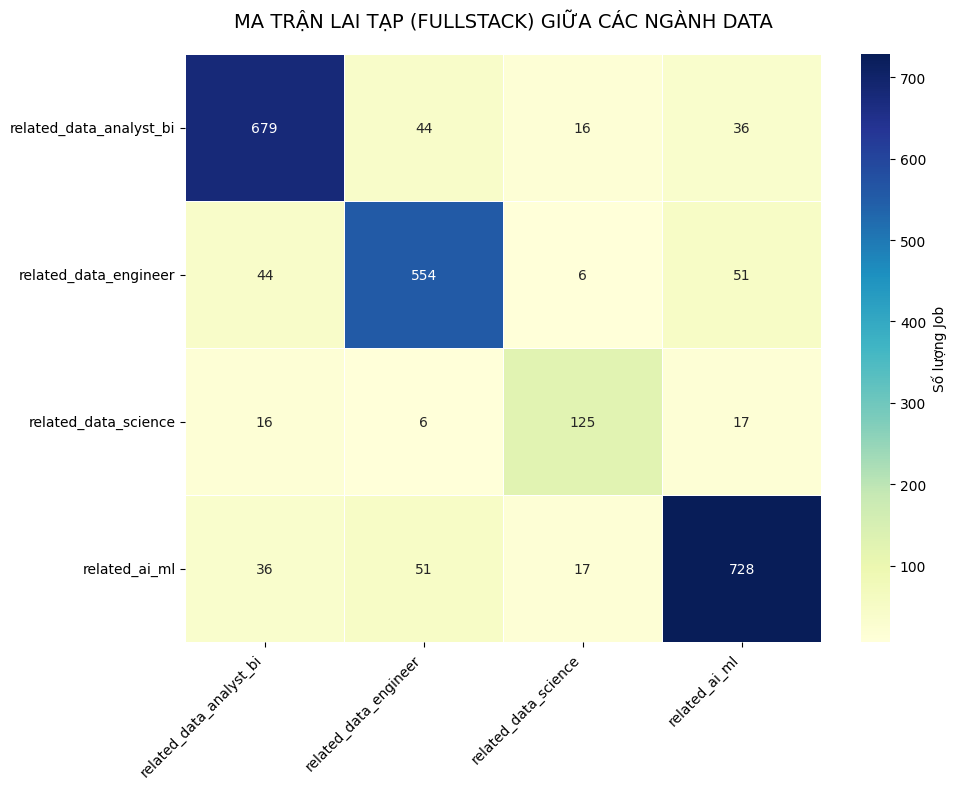

In [58]:
#  MA TRẬN JOB FULLSTACK (Giao nhau giữa các cột chuyên môn)

# 1. Khai báo 4 cột chuyên môn (Không lấy cột tổng related_data)
role_cols = [
    'related_data_analyst_bi', 
    'related_data_engineer', 
    'related_data_science', 
    'related_ai_ml'
]

# 2. Chuyển đổi các cột True/False về dạng số 1/0
matrix_df = df[role_cols].astype(int)

# 3. Tính Ma trận giao nhau bằng phép nhân ma trận (Dot Product)
co_matrix = matrix_df.T.dot(matrix_df)

print("--- MA TRẬN SỐ LƯỢNG JOB GIAO NHAU ---")
display(co_matrix)

# 4. Vẽ Heatmap (Biểu đồ nhiệt) để trực quan hóa ma trận
plt.figure(figsize=(10, 8))

# Dùng seaborn vẽ heatmap, annot=True để hiện con số, fmt='d' để hiện số nguyên
sns.heatmap(co_matrix, annot=True, fmt='d', cmap='YlGnBu', 
            linewidths=.5, cbar_kws={'label': 'Số lượng Job'})

plt.title('MA TRẬN LAI TẠP (FULLSTACK) GIỮA CÁC NGÀNH DATA', fontsize=14, pad=20)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


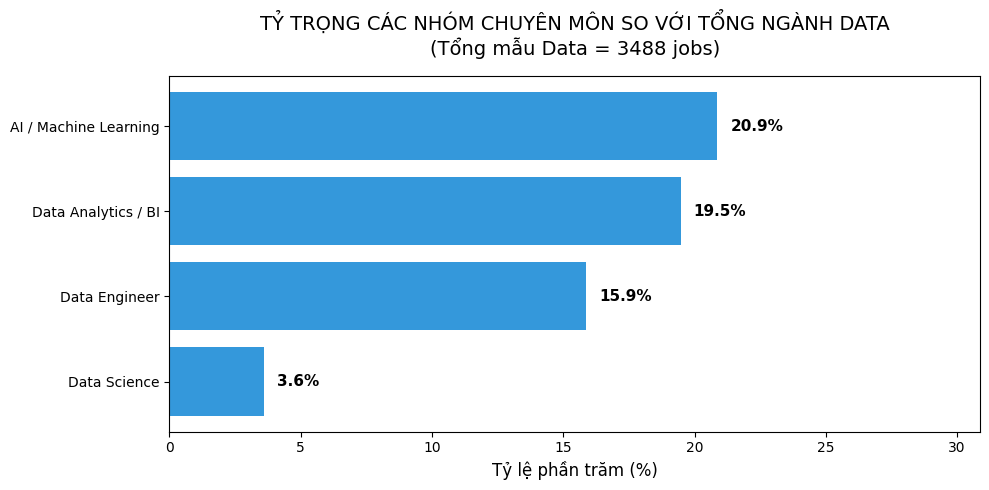

In [57]:
# 1. Khai báo dữ liệu bạn vừa thống kê
total_data_jobs = df['related_data'].sum() # Tổng là 2191

data_counts = {
    'AI / Machine Learning': df['related_ai_ml'].sum(),
    'Data Analytics / BI': df['related_data_analyst_bi'].sum(),
    'Data Engineer': df['related_data_engineer'].sum(),
    'Data Science': df['related_data_science'].sum()
}

# 2. Tính phần trăm so với tổng 2191
categories = list(data_counts.keys())
counts = list(data_counts.values())
percentages = [(count / total_data_jobs) * 100 for count in counts]

# 3. Sắp xếp từ thấp lên cao (để khi vẽ Bar ngang, cái cao nhất nằm ở trên cùng)
sorted_indices = np.argsort(percentages)
sorted_categories = [categories[i] for i in sorted_indices]
sorted_percentages = [percentages[i] for i in sorted_indices]

# 4. Vẽ biểu đồ
plt.figure(figsize=(10, 5))
# Dùng mã màu #3498db (Xanh dương nhạt) cho chuẩn tông báo cáo IT
bars = plt.barh(sorted_categories, sorted_percentages, color='#3498db') 

# 5. Thêm nhãn % vào đuôi mỗi cột
for bar in bars:
    width = bar.get_width()
    # Gắn chữ số % vào cuối cột, định dạng 1 chữ số thập phân (.1f)
    plt.text(width + 0.5, bar.get_y() + bar.get_height()/2, 
             f'{width:.1f}%', 
             ha='left', va='center', fontweight='bold', fontsize=11, color='black')

# 6. Trang trí
plt.title(f'TỶ TRỌNG CÁC NHÓM CHUYÊN MÔN SO VỚI TỔNG NGÀNH DATA\n(Tổng mẫu Data = {total_data_jobs} jobs)', fontsize=14, pad=15)
plt.xlabel('Tỷ lệ phần trăm (%)', fontsize=12)

# Nới rộng trục X ra một chút để số % không bị lẹm ra ngoài khung
plt.xlim(0, max(sorted_percentages) + 10) 

plt.tight_layout()
plt.show()


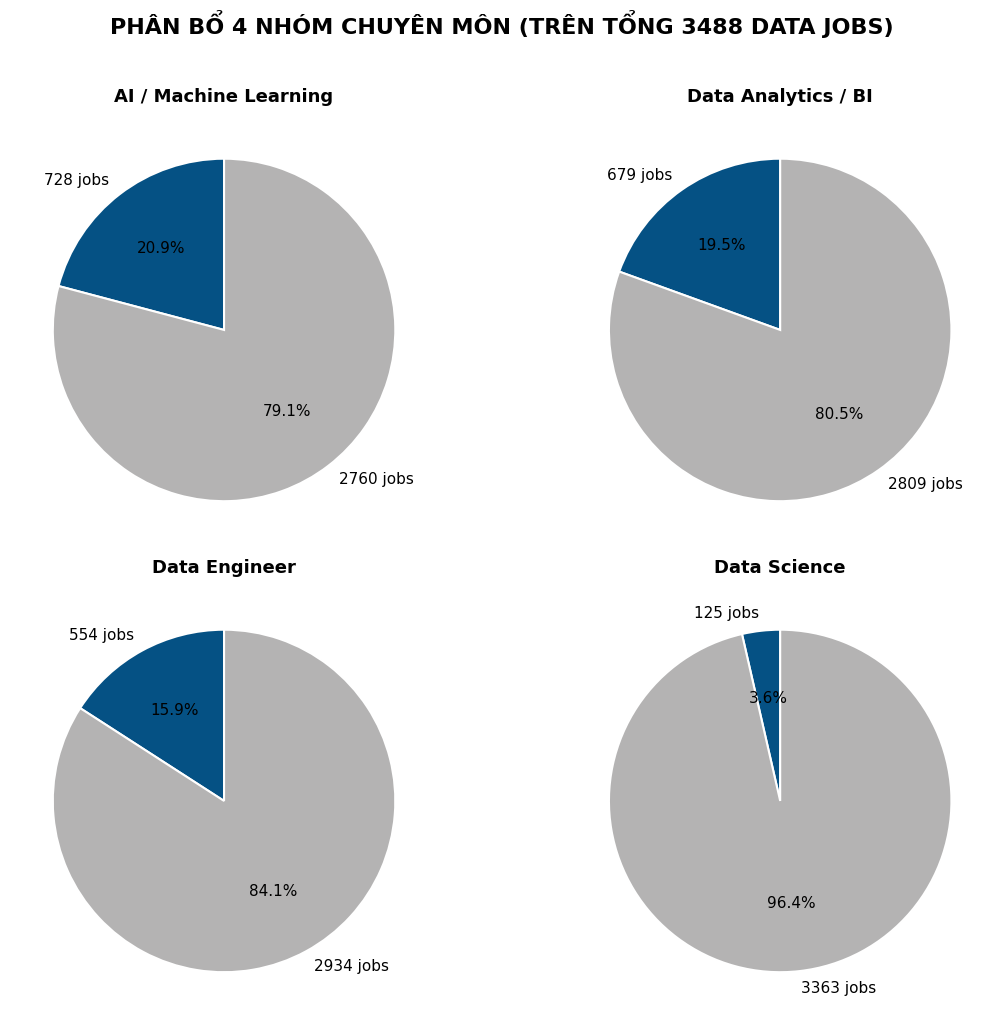

In [56]:
# 1. Tổng số Data jobs
total = df['related_data'].sum()

# 2. Khai báo danh sách 4 cột và Tên hiển thị
roles = {
    'related_ai_ml': 'AI / Machine Learning',
    'related_data_analyst_bi': 'Data Analytics / BI',
    'related_data_engineer': 'Data Engineer',
    'related_data_science': 'Data Science'
}

# 3. Tạo khung hình gồm 4 biểu đồ con (2 hàng x 2 cột)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
axes = axes.flatten() 

# Set màu chuẩn thiết kế phẳng: Xanh dương chủ đạo, Xám nhạt làm nền
colors = ["#055184", "#B4B3B3"]

# 4. Vẽ từng Pie Chart (Thiết kế phẳng, không viền, không 3D)
for i, (col_name, display_name) in enumerate(roles.items()):
    
    count_true = df[col_name].sum()
    count_false = total - count_true
    
    # Vẽ Pie Chart đơn giản, thanh lịch
    axes[i].pie(
        [count_true, count_false], 
        labels=[f'{count_true} jobs', f'{count_false} jobs'],
        autopct='%1.1f%%', 
        startangle=90,     
        colors=colors,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}, # Thêm đường viền trắng siêu mỏng để tạo khối
        textprops={'fontsize': 11}
    )
    # Đặt tên cho từng biểu đồ
    axes[i].set_title(f'{display_name}', fontweight='bold', fontsize=13, pad=10)

plt.suptitle(f'PHÂN BỔ 4 NHÓM CHUYÊN MÔN (TRÊN TỔNG {total} DATA JOBS)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 2.2 Phân loại theo lĩnh vực (Domain)
Có bổ sung lĩnh vực mới là `GAME`

In [4]:
# 1. Ghép 2 cột lại với nhau (Nếu cột nào bị NaN thì thay bằng chuỗi rỗng '')
# Thêm dấu phẩy ở giữa để text không bị dính chùm
df['combined_industry_text'] = df['company_field'].fillna('') + ", " + df['category'].fillna('')


# 2. Định nghĩa từ khóa Lĩnh vực
industry_mapping = {
    
    "Y tế": [
        "y tế", "dược", "chăm sóc sức khỏe", "làm đẹp",
        "mỹ phẩm", "thiết bị y tế", "medical", "hospital",
        "healthcare", "pharma", "dược phẩm", "thú y",
    ],
    "Game": [
        "game", "gaming", "esport",
    ],
    "Giáo dục": [
        "giáo dục", "đào tạo", "education", "edtech", "trường học",
    ],
    
    "Nhân sự": [  
        "nhân sự", "nhân lực", "staffing", "recruiting", "tuyển dụng",
        "human resource", "hr", "hành chính", "administration",
],
    
    "Tài chính - Ngân hàng": [
        "ngân hàng", "tài chính", "chứng khoán", "bảo hiểm",
        "finance", "banking", "fintech", "đầu tư", "credit",
        "financial services", "kế toán", "kiểm toán",
        "securities", "investment", "insurance",
        "luật", "pháp lý", "legal", 
    ],
    "Thương mại điện tử - Bán lẻ": [
        "thương mại điện tử", "e-commerce", "e-com",
        "bán lẻ", "bán sỉ", "bán hàng", "fmcg", "hàng tiêu dùng", "consumer goods",
        "thực phẩm", "đồ uống", "food and beverage",
        "retail and wholesale", "retail", "wholesale",
        "thời trang", "trang sức", "fashion", "apparel",
        "bao bì", "in ấn",
    ],
    "Sản xuất - Logistics": [
        "sản xuất", "xây dựng", "logistic", "vận tải",
        "kho vận", "kho bãi", "hậu cần", "giao nhận",
        "chuỗi cung ứng", "supply chain", "commercial",
        "cơ khí", "tự động hóa", "dầu khí", "khai khoáng",
        "điện tử", "điện lạnh", "dệt may", "nhựa", "nông nghiệp",
        "manufacturing", "engineering", "hoá chất", "hoá sinh",
        "ô tô", "automotive", "nhập khẩu", "xuất khẩu",
        "xuất nhập khẩu", "nội thất", "gỗ", "kiến trúc", "materials and mining",
    ],
    "Dịch vụ - Truyền thông": [
        "nhà hàng", "khách sạn", "du lịch", "hospitality",
        "marketing", "quảng cáo", "advertising", "phân tích thị trường",
        "bất động sản", "real estate", "property",
        "truyền thông", "media", "giải trí", "entertainment", "báo chí",
        "kinh doanh", "tư vấn", "consulting", 
        "creative", "design", "sports", "fitness",
    ],
    "Công nghệ - Phần mềm": [
        "phần mềm", "cntt", "công nghệ thông tin", "it services",
        "it consulting", "it hardware", "phần cứng", "cyber security",
        "viễn thông", "telecommunication", "cloud", "software",
        "công nghệ", "bưu chính", "tự động hoá", "tự động hóa",
    ],
}

# 3. Hàm quét từ khóa
def extract_industry(text):
    text_lower = str(text).lower()
    
    for industry, keywords in industry_mapping.items():
        for keyword in keywords:
            if keyword in text_lower:
                return industry
            
    return "Khác"


# 4. Áp dụng hàm để tạo cột Lĩnh vực công ty cuối cùng
df['job_industry'] = df['combined_industry_text'].apply(extract_industry)

# In kết quả thống kê
print(df['job_industry'].value_counts())


job_industry
Tài chính - Ngân hàng          1423
Công nghệ - Phần mềm           1080
Thương mại điện tử - Bán lẻ     758
Sản xuất - Logistics            687
Dịch vụ - Truyền thông          632
Giáo dục                        235
Y tế                            178
Nhân sự                         128
Khác                            110
Game                             31
Name: count, dtype: int64


In [5]:
# CÔNG TY NÀO CÓ CHỮ "EDU" THÌ ÉP LĨNH VỰC CÔNG VIỆC THÀNH "GIÁO DỤC"

# 1. Tìm bất kỳ công ty nào có chứa 3 chữ "edu" (ví dụ: EDUPIA)
edu_mask = df['company_name'].fillna('').str.lower().str.contains('edu', regex=False)
# 2. Ép (ghi đè) giá trị cột job_industry thành 'Giáo dục'
df.loc[edu_mask, 'job_industry'] = 'Giáo dục'

# In kết quả thống kê
print(df['job_industry'].value_counts())

job_industry
Tài chính - Ngân hàng          1423
Công nghệ - Phần mềm           1080
Thương mại điện tử - Bán lẻ     758
Sản xuất - Logistics            687
Dịch vụ - Truyền thông          632
Giáo dục                        246
Y tế                            178
Nhân sự                         128
Khác                             99
Game                             31
Name: count, dtype: int64


In [10]:
# CÔNG TY NÀO CÓ CHỮ "bank" OR "ngân hàng" THÌ ÉP LĨNH VỰC CÔNG VIỆC THÀNH "TÀI CHÍNH - NGÂN HÀNG"

# 1. Tìm bất kỳ công ty nào có chứa chữ "bank" hoặc "ngân hàng" (ví dụ: MB Bank)
edu_mask = df['company_name'].fillna('').str.lower().str.contains('bank|ngân hàng', regex=True)
# 2. Ép (ghi đè) giá trị cột job_industry thành 'Tài chính - Ngân hàng'
df.loc[edu_mask, 'job_industry'] = 'Tài chính - Ngân hàng'

# In kết quả thống kê
print(df['job_industry'].value_counts())

job_industry
Tài chính - Ngân hàng          1467
Công nghệ - Phần mềm           1055
Thương mại điện tử - Bán lẻ     756
Sản xuất - Logistics            687
Dịch vụ - Truyền thông          629
Giáo dục                        245
Y tế                            177
Nhân sự                         124
Khác                             83
Game                             39
Name: count, dtype: int64


In [6]:
df[['combined_industry_text', 'job_industry', 'company_name', 'job_title']]

,combined_industry_text,job_industry,company_name,job_title
0,"Ngân hàng, Kiểm Toán",Tài chính - Ngân hàng,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Kiểm Toán Viên / Kiểm Toán Nội Bộ
1,"Hệ thống CNTT & Thiết bị, Data Engineer/Data A...",Công nghệ - Phần mềm,"Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...","Kỹ Sư Phát Triển Nền Tảng, Hệ Thống"
2,"Thời trang/Trang sức, Tiếp Thị",Thương mại điện tử - Bán lẻ,Trang Văn hóa công ty,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế
3,"Nông nghiệp/Lâm nghiệp/Nuôi trồng thủy sản, Nô...",Sản xuất - Logistics,CÔNG TY TNHH MUYUAN VIỆT NAM,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...
4,"Sản xuất, Thiết Kế Công Nghiệp/Kỹ Thuật",Sản xuất - Logistics,CÔNG TY TNHH DỆT REGENT VIỆT NAM,IE Engineer
...,...,...,...,...
5257,", Quảng cáo / Đối ngoại / Truyền Thông , Giáo ...",Giáo dục,Công ty Cổ phần Masscom Việt Nam,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...
5258,", CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe /...",Y tế,Công ty Cổ phần Masscom Việt Nam,"AI Engineer (Python, LLM & AI Agents)"
5259,", CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - P...",Thương mại điện tử - Bán lẻ,Công ty Cổ phần Tập đoàn Hoa Sen,Kỹ sư Trí tuệ nhân tạo (AI Engineer)
5260,", CNTT - Phần mềm , CNTT - Phần cứng / Mạng , ...",Sản xuất - Logistics,Summit Polymers Vietnam Co Ltd.,IT Engineer - Identity & Access Management (Gl...


In [7]:
# TITLE JOB NÀO CÓ CHỮ "GAME" THÌ ÉP LĨNH VỰC CÔNG VIỆC THÀNH "Game"

# 1. Tìm bất kỳ job title nào có chứa 4 chữ "game" (ví dụ: Product Owner (Game))
game_mask = df['job_title'].fillna('').str.lower().str.contains('game', regex=False)
# 2. Ép (ghi đè) giá trị cột job_industry thành 'Giáo dục'
df.loc[game_mask, 'job_industry'] = 'Game'

# In kết quả thống kê
print(df['job_industry'].value_counts())

job_industry
Tài chính - Ngân hàng          1423
Công nghệ - Phần mềm           1076
Thương mại điện tử - Bán lẻ     756
Sản xuất - Logistics            687
Dịch vụ - Truyền thông          630
Giáo dục                        246
Y tế                            178
Nhân sự                         128
Khác                             99
Game                             39
Name: count, dtype: int64


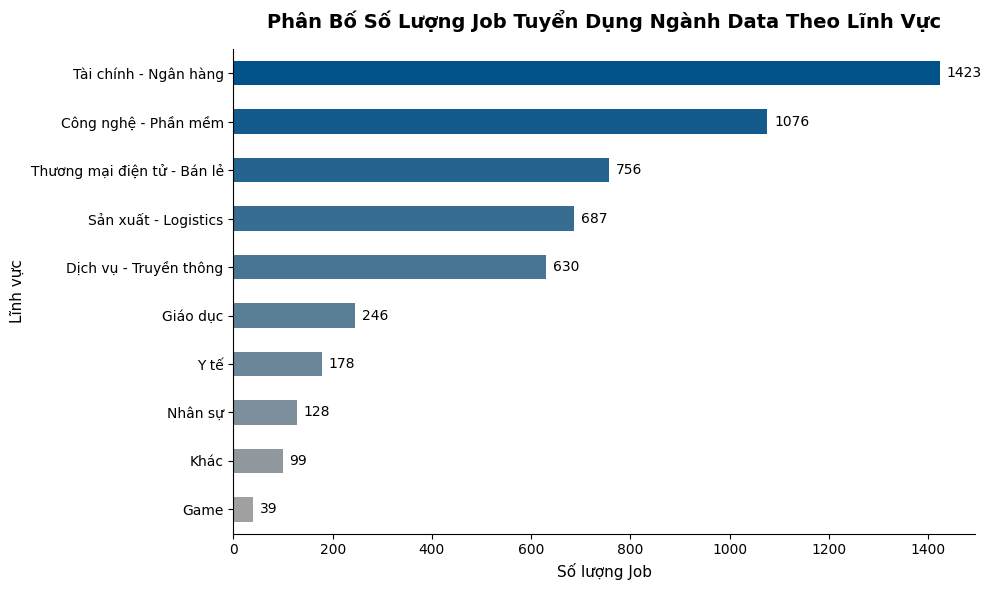

In [4]:
# 1. Đếm số lượng, sắp xếp tăng dần để ngành nhiều nhất nằm ở TRÊN CÙNG
industry_counts = df["job_industry"].value_counts().sort_values(ascending=True)


# TẠO MÀU GRADIENT: Từ xám (thanh ngắn nhất ở dưới) đến xanh blue đậm (thanh dài nhất ở trên)
# Sử dụng LinearSegmentedColormap để định nghĩa dải màu từ xám sang xanh đậm
from matplotlib.colors import LinearSegmentedColormap

colors_list = ["#A0A0A0", "#015389"]  # Xám đến Xanh blue đậm
custom_cmap = LinearSegmentedColormap.from_list("gray_to_blue", colors_list)
# Tạo danh sách màu tương ứng với số lượng thanh
gradient_colors = custom_cmap(np.linspace(0, 1, len(industry_counts)))


# 2. Vẽ biểu đồ thanh ngang
ax = industry_counts.plot(
    kind="barh", figsize=(10, 6), color=gradient_colors, edgecolor="none"
)

# 3. Thêm các con số (Data Labels) vào đầu mỗi thanh để biểu đồ dễ đọc hơn
for container in ax.containers:
    ax.bar_label(container, padding=5, fontsize=10)

# 4. Trang trí tiêu đề và nhãn trục
plt.title(
    "Phân Bố Số Lượng Job Tuyển Dụng Ngành Data Theo Lĩnh Vực",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Số lượng Job", fontsize=11)
plt.ylabel("Lĩnh vực", fontsize=11)

# Xóa đường viền khung trên và khung phải cho biểu đồ thoáng hơn
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [50]:
## 2. SAVED lần 1
## Còn phần xác định các skill tools với English skill nữa
df.to_csv("data_merged_1.csv", index=False, encoding="utf-8-sig")

## 2.3 Phân loại skill cần có
- English
- Các loại tools / skills về chuyên môn:
1.	Kỹ năng về SQL và các loại Database
2.	Kỹ năng Python và các thư viện Data (Pandas, Numpy, Pytorch...)
3.	Kỹ năng Excel, VBA, Google Sheets.

4.	Kỹ năng Cloud (AWS, Azure, GCP) và các công cụ Modern Data Stack (dbt, Snowflake...)
5.	Kỹ năng về Big Data (Spark, Hadoop, Kafka, Lakehouse)
6.	Các ngôn ngữ lập trình khác như Java, Scala, R, C++, Go...

7.	Kỹ năng về Machine Learning, AI, Deep Learning, GenAI.
8.	Kỹ năng DevOps, Git, Docker, CI/CD, API.
9.	Công cụ BI và trực quan hóa (Power BI, Tableau, Looker...)

Em khóa dưới của bạn thực sự đã nghiên cứu rất kỹ về **Modern Data Stack (Kiến trúc dữ liệu hiện đại)** và hệ sinh thái của ngành Data! Cách chia 9 nhóm này không phải là chia bừa, mà nó bám sát tuyệt đối vào lộ trình công nghệ (Tech Stack) thực tế của một vòng đời dữ liệu.

Mình sẽ giải thích lý do tại sao em ấy lại chia thành 9 nhóm này. Nó tương ứng với **chức năng và vị trí của các nhóm nghề Data**:

### 1. Nhóm nền tảng cơ bản (Must-have)
*   **Nhóm 1 (SQL & Database):** Đây là "ngôn ngữ mẹ đẻ" của ngành Data. Dù bạn là DA, DE hay DS, bạn đều phải biết SQL để lấy dữ liệu ra khỏi kho.
*   **Nhóm 2 (Python & Thư viện):** Ngôn ngữ số 1 hiện nay để thao tác dữ liệu phức tạp. Dùng cho cả việc dọn rác (DE), phân tích (DA) và huấn luyện AI (DS).
*   **Nhóm 3 (Excel, VBA, GG Sheets):** Vũ khí truyền thống. Đây là kỹ năng sinh tồn của Business Analyst và Data Analyst khi làm việc với các sếp không biết về code.

### 2. Nhóm phục vụ xây dựng hạ tầng (Của Data Engineer)
*   **Nhóm 4 (Cloud & Modern Data Stack):** Thế giới hiện nay đã chuyển lên Đám mây (AWS, GCP). Đây là kỹ năng sống còn của thế hệ Data Engineer mới (còn gọi là Cloud Data Engineer hoặc Analytics Engineer).
*   **Nhóm 5 (Big Data: Spark, Hadoop, Kafka):** Khi dữ liệu quá khổng lồ (hàng tỷ dòng mỗi ngày) mà SQL và Python bình thường bị treo, người ta phải dùng Big Data. Đây là "lãnh địa riêng" của các Big Data Engineer xịn xò.
*   **Nhóm 6 (Java, Scala, C++, Go):** Để viết ra các hệ thống Big Data ở Nhóm 5 hoạt động với tốc độ ánh sáng, Python là quá chậm. Kỹ sư phải dùng Scala, Java, C++. Nhóm này dùng để phân biệt Data Engineer với dân Software Engineer.

### 3. Nhóm phục vụ phân tích & Trình bày (Của Data Analyst)
*   **Nhóm 9 (Công cụ BI: PowerBI, Tableau):** Chén cơm manh áo của Data Analyst/BI. Sau khi data được làm sạch, đây là các tool để vẽ biểu đồ và tạo Dashboard cho sếp xem.

### 4. Nhóm phục vụ Trí tuệ nhân tạo (Của Data Scientist / AI Engineer)
*   **Nhóm 7 (ML, AI, GenAI):** Nhóm kỹ năng thuật toán, toán học và đào tạo mô hình dự báo. Đây là điểm nhấn phân biệt một Data Scientist với một Analyst thông thường.

### 5. Nhóm đưa sản phẩm vào thực tế (Deployment)
*   **Nhóm 8 (DevOps, Git, Docker, CI/CD):** Sau khi Data Scientist tạo ra con AI, hay Data Engineer viết xong đường ống, làm sao để đưa nó lên Website cho người dùng xài? Đó là lúc cần nhóm kỹ năng số 8 (MLOps / DataOps).

---
**💡 ỨNG DỤNG CHO ĐỒ ÁN CỦA BẠN:**
Cách chia 9 nhóm này là một **bước đệm hoàn hảo** để vẽ biểu đồ **Radar Chart (Biểu đồ mạng nhện)**. 
Ví dụ: Khi bạn lọc riêng nhóm "Data Analyst", màng nhện sẽ phình to ở Nhóm 1, Nhóm 6, Nhóm 9. Nhưng khi đổi sang "Data Engineer", màng nhện sẽ lập tức co lại ở nhóm 6 và phình to ở Nhóm 4, 5, 8. 

Bạn hoàn toàn có thể "mượn" cấu trúc 9 nhóm này của em khóa dưới để làm Feature Engineering (tạo 9 cột True/False) y hệt như cách bạn đã làm phân loại chức danh vậy! Đảm bảo báo cáo sẽ cực kỳ sâu sắc!

In [2]:
# review file data
filename_1 = r"data_merged_1.csv"

df=pd.read_csv(filename_1)
df

,job_url,search_keyword,job_title,company_name,location,salary,date_posted,date_deadline,category,company_field,...,req_big_data,req_other_programming,req_ai_ml,req_devops,req_bi_viz,req_english,financial_benefits,health_benefits,training_growth_benefits,culture_benefits
0,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,2026-03-27,2026-04-26,Kiểm Toán,Ngân hàng,...,False,False,False,False,True,False,False,False,True,False
1,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,2026-03-27,2026-04-26,Data Engineer/Data Analyst/AI,Hệ thống CNTT & Thiết bị,...,False,True,False,False,False,False,True,True,False,False
2,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,2026-03-27,2026-04-26,Tiếp Thị,Thời trang/Trang sức,...,False,False,False,False,True,True,True,True,False,False
3,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,2026-03-27,2026-04-26,Nông/Lâm/Ngư nghiệp,Nông nghiệp/Lâm nghiệp/Nuôi trồng thủy sản,...,False,False,False,False,False,False,True,True,True,False
4,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,2026-03-27,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,Sản xuất,...,False,False,False,False,False,True,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5257,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,15 Tr - 25 Tr VND,2026-06-11,2026-07-11,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",NaN,...,False,False,True,False,False,True,True,True,True,True
5258,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,18 Tr - 25 Tr VND,2026-06-11,2026-07-11,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",NaN,...,False,False,True,True,False,True,True,True,True,True
5259,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,Cạnh tranh,2026-06-10,2026-07-10,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",NaN,...,False,False,False,False,False,True,True,True,False,False
5260,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,Cạnh tranh,2026-06-12,2026-07-31,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng , Sả...",NaN,...,False,False,False,False,True,True,True,True,True,True


In [4]:
# 1. Ghép các cột: 'description', 'requirements', 'benefits'
# Thêm dấu phẩy ở giữa để text không bị dính chùm
df['combined_skills_text'] = df['description'].fillna('') + ", " + df['requirements'].fillna('') + ", " + df['benefits'].fillna('')

In [6]:
# ============================================================
# 1. Khai báo từ điển 9 nhóm kỹ năng
# ============================================================
skills_mapping = {
    "req_english": [
        'english', 'toeic', 'ielts', 'toefl', 'tiếng anh', 'ngôn ngữ anh',
    ],     

    "req_sql": [
        'sql', 'oracle', 'mysql', 'sql server', 'postgresql',
        'database', 'data warehouse', 'data mart', 'datamart',
        'neo4j', 'cơ sở dữ liệu', 'bigquery',
    ],

    "req_python": [
        'python', 'pandas', 'numpy', 'scipy', 'matplotlib', 'seaborn',
        'scikit-learn', 'sklearn', 'pytorch', 'tensorflow', 'pyspark',
    ],

    "req_excel": [
        'excel', 'vba', 'google sheet', 'spreadsheet', 'gsheet', 'gg sheet',
        'pivot table', 'power query', 'power pivot', 'macro',
    ],

    "req_cloud_mordern_stack": [
        'aws', 'azure', 'gcp', 'google cloud', 'google bigquery', 'bigquery',
        'snowflake', 'redshift', 'amazon athena', 'databricks',
        'microsoft fabric', 'sap bw', 'dbt', 'airflow',
    ],

    "req_big_data": [
        'spark', 'pyspark', 'hadoop', 'kafka', 'lakehouse', 'big data',
        'apache superset', 'databricks',
    ],

    "req_other_programming": [
        'java', 'javascript', 'typescript', 'scala', 'kotlin', 'go',
        'ruby', 'php', 'c++', 'c#', 'c#.net', 'visual basic', 'vb.net',
        'sas',  # SAS: Statistical Analysis System
    ],

    "req_ai_ml": [
        # Khái niệm chung
        'machine learning', 'deep learning', 'artificial intelligence',
        'generative ai', 'genai', 'gen ai', 'nlp', 'computer vision',
        'llm', 'agentic',

        # Thư viện / framework
        'pytorch', 'tensorflow',

        # Job title / vai trò liên quan AI-ML (dùng để bắt các JD ghi title thay vì kỹ năng)
        'ai engineer', 'ai expert', 'ai developer', 'ai software engineer',
        'nlp engineer', 'algorithm engineer', 'ml engineer',
        'machine learning ops engineer', 'mlops',
        'data annotation',

        # Tiếng Việt
        'kỹ sư trí tuệ nhân tạo', 'kỹ sư ai',
    ],

    "req_devops": [
        'git', 'docker', 'ci/cd', 'ci-cd', 'kubernetes', 'jenkins',
        'mlops', 'dataops', 'power automate', 'automation anywhere',
    ],

    "req_bi_viz": [
        'power bi', 'tableau', 'looker studio', 'looker', 'qlikview',
        'qliksense', 'metabase', 'mode analytics', 'data studio',
        'dashboard', 
        'google analytics', 'ga4', 'hotjar', 'microsoft clarity',
        'shopify analytics', 'customer data platform', 'customer data platforms', ' cdp ',  # nhóm đo lường/tracking gộp tạm vào BI & Viz
    ],
}


# ============================================================
# 2. Hàm build regex pattern an toàn cho cả từ khóa có ký tự đặc biệt
# ============================================================
def build_pattern(kw):
    kw = kw.strip().lower()
    escaped = re.escape(kw)
    # Nếu từ khóa chỉ gồm chữ/số/khoảng trắng -> dùng \b để tránh match nhầm 1 phần của từ khác
    if re.fullmatch(r'[a-z0-9\s]+', kw):
        return r'\b' + escaped + r'\b'
    # Từ khóa có ký tự đặc biệt (c++, c#, ci/cd...) -> match substring trực tiếp
    return escaped


# Pre-compile toàn bộ pattern cho mỗi nhóm để chạy nhanh hơn
compiled_patterns = {
    col: [re.compile(build_pattern(kw)) for kw in kws]
    for col, kws in skills_mapping.items()
}


# ============================================================
# 3. Hàm quét cột combined_skills_text và tạo 9 cột mới
# ============================================================
def feature_engineering_skills(df, text_col='combined_skills_text'):
    for col in skills_mapping.keys():
        df[col] = False

    def check_skills(row):
        text = str(row[text_col]).lower()
        for col, patterns in compiled_patterns.items():
            for pat in patterns:
                if pat.search(text):
                    row[col] = True
                    break
        return row

    df = df.apply(check_skills, axis=1)
    return df


# Chạy
df = feature_engineering_skills(df)

# Thống kê nhanh
print("Thống kê số lượng (True) theo từng nhóm kỹ năng:")
for col in skills_mapping.keys():
    print(f"{col}: {df[col].sum()} jobs")

Thống kê số lượng (True) theo từng nhóm kỹ năng:
req_english: 2513 jobs
req_sql: 2080 jobs
req_python: 1444 jobs
req_excel: 1337 jobs
req_cloud_mordern_stack: 985 jobs
req_big_data: 626 jobs
req_other_programming: 842 jobs
req_ai_ml: 1019 jobs
req_devops: 976 jobs
req_bi_viz: 1212 jobs


In [4]:
# Bổ sung job liên quan data, nhưng mô tả mới có chữ "data"

def add_data_condition(row):
    text = str(row['combined_skills_text']).lower()
    has_data_keyword = bool(re.search(r'\bdata\b', text)) or "dữ liệu" in text
    return row['related_data'] or has_data_keyword

df['related_data'] = df.apply(add_data_condition, axis=1)

print(f"Tổng số jobs related_data sau khi cập nhật: {df['related_data'].sum()}")

Tổng số jobs related_data sau khi cập nhật: 4385


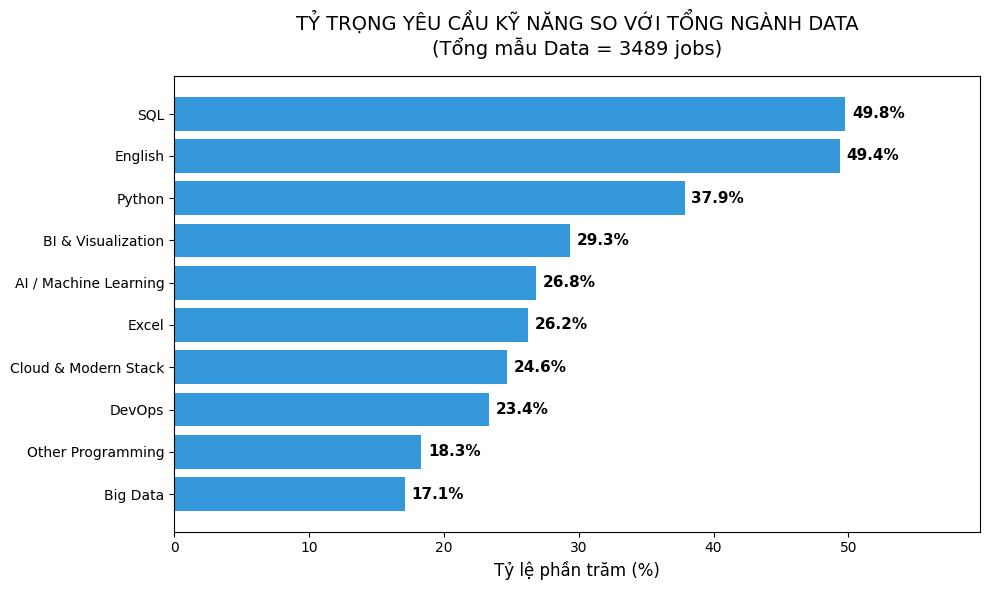

In [17]:
# 1. Khai báo dữ liệu thống kê 10 nhóm kỹ năng
total_data_jobs = df['related_data'].sum()  # lấy tự động từ cột related_data hiện tại

skill_counts = {
    'English': df['req_english'].sum(),
    'SQL': df['req_sql'].sum(),
    'Python': df['req_python'].sum(),
    'Excel': df['req_excel'].sum(),
    'Cloud & Modern Stack': df['req_cloud_mordern_stack'].sum(),
    'Big Data': df['req_big_data'].sum(),
    'Other Programming': df['req_other_programming'].sum(),
    'AI / Machine Learning': df['req_ai_ml'].sum(),
    'DevOps': df['req_devops'].sum(),
    'BI & Visualization': df['req_bi_viz'].sum(),
}

# 2. Tính phần trăm so với tổng related_data
categories = list(skill_counts.keys())
counts = list(skill_counts.values())
percentages = [(count / total_data_jobs) * 100 for count in counts]

# 3. Sắp xếp từ thấp lên cao (để khi vẽ Bar ngang, cái cao nhất nằm ở trên cùng)
sorted_indices = np.argsort(percentages)
sorted_categories = [categories[i] for i in sorted_indices]
sorted_percentages = [percentages[i] for i in sorted_indices]

# 4. Vẽ biểu đồ
plt.figure(figsize=(10, 6))
bars = plt.barh(sorted_categories, sorted_percentages, color='#3498db')

# 5. Thêm nhãn % vào đuôi mỗi cột
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.5, bar.get_y() + bar.get_height()/2,
              f'{width:.1f}%',
              ha='left', va='center', fontweight='bold', fontsize=11, color='black')

# 6. Trang trí
plt.title(f'TỶ TRỌNG YÊU CẦU KỸ NĂNG SO VỚI TỔNG NGÀNH DATA\n(Tổng mẫu Data = {total_data_jobs} jobs)', fontsize=14, pad=15)
plt.xlabel('Tỷ lệ phần trăm (%)', fontsize=12)

plt.xlim(0, max(sorted_percentages) + 10)

plt.tight_layout()
plt.show()

In [8]:
# Check các job không liên quan data

result = df.loc[~df['related_data'], ['job_title', 'description']]
result

,job_title,description
0,Kiểm Toán Viên / Kiểm Toán Nội Bộ,MÔ TẢ CÔNG VIỆC 1. Thực hiện công việc thuộc c...
1,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","1) Tham gia thiết kế kiến trúc, phát triển chứ..."
2,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,"Mục đích vị trí công việc Triển khai, theo dõi..."
3,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,Mô tả công việc: 1. Quan hệ chính phủ & kết nố...
5,Solar Project Development Specialist (Chuyên V...,"'- Chủ động tìm kiếm, trực tiếp tiếp cận khách..."
...,...,...
5244,Trưởng phòng Giải pháp kinh doanh số - Khối Kh...,Nhiệm vụ quản lý:. Điều hành hoạt động chung c...
5245,Chuyên viên Planning & Performance,Quản trị & Điều phối kế hoạch kinh doanh. Phối...
5246,Business Analyst,"Tiến hành khảo sát, thu thập yêu cầu và các ..."
5248,Business Analyst ERP (Long An),"Lô B4B5B6 Đường số 1, Khu Công Nghiệp Thuận Đạ..."


In [7]:
## SAVED lần 1
## Còn phần xác định các skill tools với English skill nữa
df.to_csv("data_merged_1.csv", index=False, encoding="utf-8-sig")

## 2.4 Phân loại các Phúc lợi công việc
- Bảo hiểm, chăm sóc sức khỏe, Gym.	`has_health_wellness_benefits`
- Đào tạo, học bổng, lộ trình thăng tiến.	`has_training_growth_benefits`
- Du lịch, Team building, cung cấp Macbook/Laptop.	`has_lifestyle_culture_benefits`

In [11]:
df['benefits']

0                                            Đào tạo|Khác
1                                Thưởng|Chăm sóc sức khoẻ
2             Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương
3                   Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác
4                                     Thưởng|Đào tạo|Khác
                              ...                        
5257    Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...
5258    Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...
5259    Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...
5260    Laptop. Chế độ bảo hiểm. Du Lịch. Đồng phục. C...
5261    Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...
Name: benefits, Length: 5262, dtype: object

In [21]:
import re

# ============================================================
# 1. Khai báo từ điển 4 nhóm phúc lợi (Benefits)
# ============================================================
benefits_mapping = {
    "financial_benefits": [
        'lương', 'thưởng', 'lương tháng 13', 'lương tháng thứ 13', 
        'phụ cấp', "thu nhập", 'compensation', 'income', '13th payment',
        'salary', 'bonus', '13th month', 'esop', 'nghỉ phép có lương', 
    ],     

    "health_benefits": [
        'bảo hiểm', 'chăm sóc', 'sức khỏe', 'gym', 'fitness', 'y tế', 
        'insurance', 'medical', 'healthcare', 'bhxh', 'bhyt', 'bhtn', 'tai nạn'
    ],

    "training_growth_benefits": [
        'đào tạo', 'training', 'mentorship', 'coaching', 'learning', 'growth',
        'học bổng', 'thăng tiến', 'career path', 'nâng cao nghiệp vụ', 'phát triển',
        'certificate', 'certification', 'mentor', 'mentoring', 'course'
    ],

    "culture_benefits": [
        'du lịch', 'team building', 'company trip', 'holiday', 'party', 'event', 'celebration', 'gift', 'work from home',
        'macbook', 'laptop', 'hoạt động nhóm', 'máy tính', 'remote', 'flexible', 'equipment provided', 'wfh', 'trip',
    ],
}

# ============================================================
# 2. Hàm build regex pattern an toàn (Giữ nguyên logic của bạn)
# ============================================================
def build_benefit_pattern(kw):
    kw = kw.strip().lower()
    escaped = re.escape(kw)
    # Nếu từ khóa chỉ gồm chữ/số/khoảng trắng/tiếng Việt không dấu -> dùng \b để tránh match nhầm 1 phần của từ khác
    # Bổ sung các ký tự tiếng Việt phổ biến vào regex gốc của bạn để bắt ranh giới từ tiếng Việt chuẩn hơn
    if re.fullmatch(r'[a-z0-9\sàáạảãâầấậẩẫăằắặẳẵèéẹẻẽêềếệểễđìíịỉĩòóọỏõôồốộổỗơờớợởỡùúụủũưừứựửữỳýỵỷỹ]+', kw):
        return r'\b' + escaped + r'\b'
    return escaped

# Pre-compile toàn bộ pattern cho mỗi nhóm để chạy tối ưu hiệu năng
compiled_benefit_patterns = {
    col: [re.compile(build_benefit_pattern(kw)) for kw in kws]
    for col, kws in benefits_mapping.items()
}

# ============================================================
# 3. Hàm quét cột benefits và tạo 4 cột phúc lợi mới
# ============================================================
def feature_engineering_benefits(df, text_col='benefits'):
    # Khởi tạo giá trị False cho cả 4 cột mới
    for col in benefits_mapping.keys():
        df[col] = False

    def check_benefits(row):
        # Chuyển chữ về lower để không phân biệt hoa thường
        text = str(row[text_col]).lower()
        
        # Quét qua từng nhóm phúc lợi
        for col, patterns in compiled_benefit_patterns.items():
            for pat in patterns:
                if pat.search(text):
                    row[col] = True
                    break # Tìm thấy 1 từ khóa trong nhóm là đủ, nhảy sang nhóm tiếp theo
        return row

    # Áp dụng hàm xử lý trên từng dòng của dataframe
    df = df.apply(check_benefits, axis=1)
    return df

# ============================================================
# 4. Thực thi và Thống kê dữ liệu
# ============================================================
# Chạy hàm xử lý tạo tính năng mới
df = feature_engineering_benefits(df)

# In thống kê nhanh số lượng True thu được
print("Thống kê số lượng (True) theo từng nhóm phúc lợi:")
for col in benefits_mapping.keys():
    print(f"{col}: {df[col].sum()} jobs")


Thống kê số lượng (True) theo từng nhóm phúc lợi:
financial_benefits: 4762 jobs
health_benefits: 4058 jobs
training_growth_benefits: 3233 jobs
culture_benefits: 3116 jobs


In [22]:
# Điều kiện 1: 'benefits' khác "Khác" và chứa ít nhất 1 ký tự chữ cái (tiếng Việt/Anh)
cond1 = (df['benefits'].astype(str).str.strip() != "Khác") & \
        df['benefits'].str.contains(r'[^\W\d_]', na=False)

# Điều kiện 2: Cả 3 cột Boolean đều bằng False
# Dùng toán tử ~ để phủ định (nghĩa là NOT True)
cond2 = ~df['health_benefits'] & \
        ~df['training_growth_benefits'] & \
        ~df['financial_benefits'] & \
        ~df['culture_benefits']

# Lọc và hiển thị kết quả
result_df = df[cond2]
result_df['benefits']

6          Khác
13         Khác
36      Căn-tin
42         Khác
44         Khác
         ...   
5145        NaN
5148        NaN
5149        NaN
5161        NaN
5215        NaN
Name: benefits, Length: 200, dtype: object

In [21]:
df[['benefits', 'financial_benefits', 'health_benefits', 'training_growth_benefits', 'culture_benefits']]

,benefits,financial_benefits,health_benefits,training_growth_benefits,culture_benefits
0,Đào tạo|Khác,False,False,True,False
1,Thưởng|Chăm sóc sức khoẻ,True,True,False,False
2,Thưởng|Chăm sóc sức khoẻ|Nghỉ phép có lương,True,True,False,False
3,Thưởng|Chăm sóc sức khoẻ|Đào tạo|Khác,True,True,True,False
4,Thưởng|Đào tạo|Khác,True,False,True,False
...,...,...,...,...,...
5257,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,True,True,True,True
5258,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,True,True,True,True
5259,Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...,True,True,False,False
5260,Laptop. Chế độ bảo hiểm. Du Lịch. Đồng phục. C...,True,True,True,True


## 2.5 Chỉnh sửa lại phần SOURCE
- 1 = Vietnamworks
- 2 = ITviec
- 3 = TopCV
- 4 = CareerViet

In [9]:
# Khai báo từ điển ánh xạ mã nguồn sang tên text
source_mapping = {
    1: 'Vietnamworks',
    2: 'ITviec',
    3: 'TopCV',
    4: 'CareerViet'
}

# Tiến hành ghi đè dữ liệu mới lên cột source
df['source'] = df['source'].map(source_mapping)

In [10]:
df['source'].value_counts()

source
Vietnamworks    2406
ITviec          1148
CareerViet       919
TopCV            789
Name: count, dtype: int64

# 3. XÓA BỎ NHỮNG JOB KO LIÊN QUAN DATA
1. Xóa dòng ko liên quan data

2. Xóa cột dư thừa ko vẽ được dashboard: 
    - search_keyword, salary, category, company_field, 
    - min_experience, mean_salary (vì có cột fix rồi)
    - description, requirements, benefits, note_to_combine,
    - combined_industry_text
    - combined_skills_text
    - related_data (vì đã lọc loại bỏ FALSE ở bước 1)
    - salary_group (vì ko vẽ được chart)

In [6]:
df

,job_url,search_keyword,job_title,company_name,location,salary,date_posted,date_deadline,category,company_field,...,req_other_programming,req_ai_ml,req_devops,req_bi_viz,req_english,financial_benefits,health_benefits,training_growth_benefits,culture_benefits,exp_range
0,https://www.vietnamworks.com/kiem-toan-vien-ki...,Data Analyst,Kiểm Toán Viên / Kiểm Toán Nội Bộ,Ngân Hàng Thương Mại TNHH MTV Ngoại Thương Côn...,Hà Nội,Thương lượng,2026-03-27,2026-04-26,Kiểm Toán,Ngân hàng,...,False,False,False,True,False,False,False,True,False,1-3 năm
1,https://www.vietnamworks.com/ky-su-phat-trien-...,Data Analyst,"Kỹ Sư Phát Triển Nền Tảng, Hệ Thống","Viện Phát Triển Chuyển Đổi Xanh, Chuyển Đổi Số...",Hà Nội,Thương lượng,2026-03-27,2026-04-26,Data Engineer/Data Analyst/AI,Hệ thống CNTT & Thiết bị,...,True,False,False,False,False,True,True,False,False,None
2,https://www.vietnamworks.com/chuyen-vien-cao-c...,Data Analyst,Chuyên Viên Cao Cấp Vận Hành Thương Hiệu Quốc Tế,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,2026-03-27,2026-04-26,Tiếp Thị,Thời trang/Trang sức,...,False,False,False,True,True,True,True,False,False,1-3 năm
3,https://www.vietnamworks.com/nhan-vien-phat-tr...,Data Analyst,Nhân Viên Phát Triển Dự Án Nông Nghiệp (Agricu...,CÔNG TY TNHH MUYUAN VIỆT NAM,Hồ Chí Minh,16tr-30tr ₫/tháng,2026-03-27,2026-04-26,Nông/Lâm/Ngư nghiệp,Nông nghiệp/Lâm nghiệp/Nuôi trồng thủy sản,...,False,False,False,False,False,True,True,True,False,1-3 năm
4,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,2026-03-27,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,Sản xuất,...,False,False,False,False,True,True,False,True,False,1-3 năm
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5257,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,15 Tr - 25 Tr VND,2026-06-11,2026-07-11,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",NaN,...,False,True,False,False,True,True,True,True,True,Dưới 1 năm
5258,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,18 Tr - 25 Tr VND,2026-06-11,2026-07-11,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",NaN,...,False,True,True,False,True,True,True,True,True,1-3 năm
5259,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,Cạnh tranh,2026-06-10,2026-07-10,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",NaN,...,False,False,False,False,True,True,True,False,False,1-3 năm
5260,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,Cạnh tranh,2026-06-12,2026-07-31,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng , Sả...",NaN,...,False,False,False,True,True,True,True,True,True,3-5 năm


## 3.1 Xóa dòng ko liên quan Data

In [8]:
# Chỉ giữ các job có liên quan đến Data
before_count = len(df)
df2 = df[df['related_data'] == True].copy()
after_count = len(df2)

print(f"Số job trước khi lọc: {before_count}")
print(f"Số job bị loại: {before_count - after_count}")
print(f"Số job còn lại: {after_count}")
print(f"Còn job related_data=False: {(df2['related_data'] == False).sum()}")

Số job trước khi lọc: 5262
Số job bị loại: 1773
Số job còn lại: 3489
Còn job related_data=False: 0


In [9]:
df2

,job_url,search_keyword,job_title,company_name,location,salary,date_posted,date_deadline,category,company_field,...,req_other_programming,req_ai_ml,req_devops,req_bi_viz,req_english,financial_benefits,health_benefits,training_growth_benefits,culture_benefits,exp_range
4,https://www.vietnamworks.com/ie-engineer-20310...,Data Analyst,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,Thương lượng,2026-03-27,2026-04-26,Thiết Kế Công Nghiệp/Kỹ Thuật,Sản xuất,...,False,False,False,False,True,True,False,True,False,1-3 năm
6,https://www.vietnamworks.com/head-of-sourcing-...,Data Analyst,Head of Sourcing,Yes4All Trading Services Company Limited,Hồ Chí Minh,Thương lượng,2026-03-27,2026-04-26,Quản Lý Chuỗi Cung Ứng,Thương mại điện tử,...,False,False,False,False,False,False,False,False,False,3-5 năm
7,https://www.vietnamworks.com/digital-content-m...,Data Analyst,Digital & Content Manager – Thu Nhập Up to 45M,Công ty TNHHH ĐT XNK Hoan TT,Hà Nội,25tr-45tr ₫/tháng,2026-03-27,2026-04-26,Tiếp Thị Trực Tuyến,Nhập khẩu/Xuất khẩu,...,False,False,False,False,False,True,False,True,False,1-3 năm
11,https://www.vietnamworks.com/senior-media-perf...,Data Analyst,Senior Media Performance Marketing Executive,Trang Văn hóa công ty,Hồ Chí Minh,Thương lượng,2026-03-27,2026-04-26,Tiếp Thị Trực Tuyến,Làm đẹp (Mỹ phẩm) & Chăm sóc cá nhân,...,False,False,False,True,True,True,True,False,True,1-3 năm
16,https://www.vietnamworks.com/senior-digital-gr...,Data Analyst,Senior Digital Growth Executive,Công Ty Tài Chính TNHH Ngân Hàng TMCP Sài Gòn ...,Hồ Chí Minh,Thương lượng,2026-03-27,2026-04-26,Chuyển Đổi Số,Tài Chính,...,False,False,False,False,False,True,True,True,True,1-3 năm
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5256,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,AI Engineer,Công ty Cổ phần CANIFA,Hà Nội,16 Tr - 35 Tr VND,2026-06-12,2026-07-15,CNTT - Phần mềm,NaN,...,False,True,True,False,False,True,True,True,True,1-3 năm
5258,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,18 Tr - 25 Tr VND,2026-06-11,2026-07-11,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",NaN,...,False,True,True,False,True,True,True,True,True,1-3 năm
5259,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,Cạnh tranh,2026-06-10,2026-07-10,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",NaN,...,False,False,False,False,True,True,True,False,False,1-3 năm
5260,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,Cạnh tranh,2026-06-12,2026-07-31,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng , Sả...",NaN,...,False,False,False,True,True,True,True,True,True,3-5 năm


## 3.2 Xóa các cột ko cần nữa

In [10]:
# Danh sách các cột dư thừa cần xóa
columns_to_drop = [
    'search_keyword', 'salary', 'category', 'company_field', 
    'min_experience', 'mean_salary', 'salary_group',
    'description', 'requirements', 'benefits', 'note_to_combine',
    'combined_industry_text', 'combined_skills_text',
    'related_data'
]

# Thực hiện xóa cột (inplace=True để áp dụng trực tiếp thay đổi vào df2)
df2.drop(columns=columns_to_drop, errors='ignore', inplace=True)

In [11]:
df2

,job_url,job_title,company_name,location,date_posted,date_deadline,source,work_type,job_position,edu,...,req_other_programming,req_ai_ml,req_devops,req_bi_viz,req_english,financial_benefits,health_benefits,training_growth_benefits,culture_benefits,exp_range
4,https://www.vietnamworks.com/ie-engineer-20310...,IE Engineer,CÔNG TY TNHH DỆT REGENT VIỆT NAM,Phú Thọ,2026-03-27,2026-04-26,Vietnamworks,Full-time,Nhân viên,Đại học,...,False,False,False,False,True,True,False,True,False,1-3 năm
6,https://www.vietnamworks.com/head-of-sourcing-...,Head of Sourcing,Yes4All Trading Services Company Limited,Hồ Chí Minh,2026-03-27,2026-04-26,Vietnamworks,Full-time,Lãnh đạo / Quản lý,Đại học,...,False,False,False,False,False,False,False,False,False,3-5 năm
7,https://www.vietnamworks.com/digital-content-m...,Digital & Content Manager – Thu Nhập Up to 45M,Công ty TNHHH ĐT XNK Hoan TT,Hà Nội,2026-03-27,2026-04-26,Vietnamworks,Full-time,Trưởng phòng,Ko yêu cầu,...,False,False,False,False,False,True,False,True,False,1-3 năm
11,https://www.vietnamworks.com/senior-media-perf...,Senior Media Performance Marketing Executive,Trang Văn hóa công ty,Hồ Chí Minh,2026-03-27,2026-04-26,Vietnamworks,Full-time,Nhân viên,Đại học,...,False,False,False,True,True,True,True,False,True,1-3 năm
16,https://www.vietnamworks.com/senior-digital-gr...,Senior Digital Growth Executive,Công Ty Tài Chính TNHH Ngân Hàng TMCP Sài Gòn ...,Hồ Chí Minh,2026-03-27,2026-04-26,Vietnamworks,Full-time,Nhân viên,Đại học,...,False,False,False,False,False,True,True,True,True,1-3 năm
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5256,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,Công ty Cổ phần CANIFA,Hà Nội,2026-06-12,2026-07-15,CareerViet,Full-time,Nhân viên,NaN,...,False,True,True,False,False,True,True,True,True,1-3 năm
5258,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,2026-06-11,2026-07-11,CareerViet,Full-time,Nhân viên,NaN,...,False,True,True,False,True,True,True,True,True,1-3 năm
5259,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,2026-06-10,2026-07-10,CareerViet,Full-time,Nhân viên,Đại học,...,False,False,False,False,True,True,True,False,False,1-3 năm
5260,https://careerviet.vn/vi/tim-viec-lam/it-engin...,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,2026-06-12,2026-07-31,CareerViet,Full-time,Nhân viên,NaN,...,False,False,False,True,True,True,True,True,True,3-5 năm


In [12]:
## SAVED lần 2
## Đưa vào MySQL
df2.to_csv("data_merged_2.csv", index=False, encoding="utf-8-sig")

In [13]:
df['location'].value_counts()

location
Hà Nội               2487
Hồ Chí Minh          2312
Đà Nẵng                68
Bình Dương             51
Đồng Nai               49
Bắc Ninh               45
Hải Phòng              36
Nước Ngoài / Khác      25
Long An                22
Hưng Yên               20
Bà Rịa – Vũng Tàu      18
Tây Ninh               11
Gia Lai                 9
Thái Nguyên             9
Hải Dương               9
Cần Thơ                 7
Bắc Giang               6
Thanh Hoá               6
An Giang                6
Phú Thọ                 5
Khánh Hoà               5
Quảng Ngãi              3
Hà Tĩnh                 3
Ninh Bình               3
Huế                     3
Nghệ An                 3
Hà Nam                  3
Vĩnh Phúc               3
Lâm Đồng                2
Bến Tre                 2
Thái Bình               2
Đồng Tháp               2
Cà Mau                  2
Kiên Giang              2
Quảng Ninh              2
Đắk Lắk                 2
Tiền Giang              1
Lào Cai                 1
Vĩn